# Klasifikasi Kondisi Susunan Sepatu dengan Hybrid Feature Extraction

**Pendekatan:** RGB Color + GLCM Texture + HOG Shape/Gradient + LBP Local Texture + YOLO Geometric/Spatial
**Kelas:** `berantakan` dan `tidak_berantakan`
**Classifier utama:** Machine Learning klasik (tanpa CNN)

## 1. Project Overview

### Tujuan penelitian

1. Mengekstraksi fitur warna (RGB), tekstur (GLCM), bentuk/gradien (HOG), dan tekstur lokal (LBP) dari citra sepatu 256 × 256.
2. Menguji kontribusi fitur geometris dan spasial hasil deteksi objek YOLO.
3. Membandingkan tujuh algoritma Machine Learning klasik dengan Stratified 5-Fold Cross Validation.
4. Memilih model terbaik secara otomatis berdasarkan mean CV accuracy pada data training.
5. Menguji kontribusi setiap kelompok fitur melalui enam eksperimen ablation (E1–E6).
6. Mengevaluasi model final satu kali pada data testing yang tidak pernah dipakai selama pemilihan model.

### Deskripsi dataset

Dataset tersimpan di folder proyek induk, dengan salah satu struktur berikut:

```text
berantakan/          -> label "berantakan"
rapi/                -> label "tidak_berantakan"
```

atau

```text
dataset/
├── berantakan/      -> label "berantakan"
└── rapi/            -> label "tidak_berantakan"
```

Jumlah citra sekitar 194 file (97 per kelas). Notebook mendeteksi folder dataset secara otomatis dari folder induk, sehingga tetap berjalan baik dibuka dari `model.yolo/` maupun dari root proyek.

### Dua mode eksperimen

| Mode | Fitur | Syarat |
|---|---|---|
| **Mode 1 — Baseline** | RGB + GLCM + HOG + LBP (33 fitur) | Selalu dapat dijalankan |
| **Mode 2 — Hybrid YOLO** | Baseline + YOLO Geometric + Spatial (49 fitur) | Perlu model YOLO dengan kelas `shoe` |

> Dataset ini hanya memiliki label tingkat gambar, **bukan bounding box**. Karena itu YOLO tidak dilatih di dalam notebook ini. Model COCO standar juga tidak memiliki kelas `shoe`, sehingga tidak boleh diasumsikan dapat mendeteksi sepatu. Bila `YOLO_WEIGHTS` tidak diisi, notebook otomatis berjalan pada Mode 1 dan seluruh bagian YOLO dilewati dengan pesan yang jelas.

### Alur pengerjaan

```text
Loading dataset -> Preprocessing -> Ekstraksi fitur (RGB, GLCM, HOG, LBP, YOLO)
-> Integrasi CSV/Excel -> EDA -> Split 80/20 -> CV 7 model -> Feature selection
-> Tuning -> Ablation E1-E6 -> Evaluasi final -> Simpan artefak
```


## 2. Library Installation and Import

Instalasi dibuat opsional dan idempoten. Di Google Colab atau virtual environment baru, ubah `INSTALL_DEPENDENCIES = True` lalu jalankan sel instalasi **sekali**, restart kernel, kemudian jalankan notebook dari awal. `ultralytics` dipisah karena menarik dependensi PyTorch yang besar dan hanya dibutuhkan untuk Mode 2.


In [1]:
# ============================================================
# INSTALASI (opsional, jalankan sekali di environment baru)
# ============================================================
INSTALL_DEPENDENCIES = False   # ubah ke True bila paket belum tersedia
INSTALL_YOLO = False           # True hanya bila Mode 2 (YOLO) akan dipakai

if INSTALL_DEPENDENCIES:
    import subprocess
    import sys

    packages = [
        "numpy", "pandas", "matplotlib", "seaborn", "Pillow", "scikit-image",
        "scikit-learn", "scipy", "tqdm", "opencv-python", "lightgbm",
        "openpyxl", "joblib",
    ]
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])
    if INSTALL_YOLO:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
    print("Instalasi selesai. Restart kernel, lalu jalankan notebook dari awal.")
else:
    print("Instalasi dilewati (INSTALL_DEPENDENCIES = False).")


Instalasi dilewati (INSTALL_DEPENDENCIES = False).


In [2]:
# ============================================================
# IMPORT LIBRARY
# ============================================================
import hashlib
import json
import os
import pickle
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import skimage
import sklearn

os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))

from IPython.display import display
from PIL import Image, ImageOps
from skimage.feature import graycomatrix, graycoprops, hog, local_binary_pattern
from sklearn.base import clone
from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.feature_selection import RFE, SelectKBest, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import (
    GridSearchCV,
    GroupShuffleSplit,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tqdm import tqdm

try:
    from lightgbm import LGBMClassifier
    LIGHTGBM_AVAILABLE = True
except ImportError:
    LIGHTGBM_AVAILABLE = False

try:
    from ultralytics import YOLO
    ULTRALYTICS_AVAILABLE = True
except ImportError:
    ULTRALYTICS_AVAILABLE = False

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Could not find the number of physical cores")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print(f"scikit-image  : {skimage.__version__}")
print(f"scikit-learn  : {sklearn.__version__}")
print(f"LightGBM      : {'OK' if LIGHTGBM_AVAILABLE else 'tidak terpasang'}")
print(f"Ultralytics   : {'OK' if ULTRALYTICS_AVAILABLE else 'tidak terpasang'}")


scikit-image  : 0.25.2
scikit-learn  : 1.6.1
LightGBM      : OK
Ultralytics   : tidak terpasang


In [3]:
# ============================================================
# KONFIGURASI PATH, PARAMETER, DAN NAMA FITUR
# ============================================================
RANDOM_STATE = 42
IMG_SIZE = (256, 256)          # lebar, tinggi
N_SPLITS = 5
TEST_SIZE = 0.2

FORCE_RECOMPUTE = False        # True untuk mengabaikan cache CSV
SPLIT_BY_GROUP = False         # True untuk group split berdasarkan ID sepatu (24-xxx)
DROP_DUPLICATE_FILES = False   # duplikat hanya dilaporkan, tidak dihapus otomatis

# ---- YOLO (Mode 2) ----
YOLO_WEIGHTS = None            # contoh: "runs/detect/train/weights/best.pt" (kelas: shoe)
YOLO_CLASS_NAME = "shoe"
YOLO_CONF = 0.25
YOLO_IOU = 0.50
YOLO_IMG_SIZE = 640

FOLDER_TO_LABEL = {
    "berantakan": "berantakan",
    "rapi": "tidak_berantakan",
}
CLASS_LABELS = ["berantakan", "tidak_berantakan"]
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png"}

GLCM_LEVELS = 256
GLCM_DISTANCES = [1]
GLCM_ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]

RGB_FEATURES = [f"{stat}_{channel}" for stat in ("mean", "std", "skew") for channel in "RGB"]
GLCM_FEATURES = ["energy", "entropy", "contrast", "correlation", "homogeneity"]
HOG_FEATURES = [f"hog_bin_{index:02d}" for index in range(1, 10)]
LBP_FEATURES = [f"lbp_bin_{index:02d}" for index in range(10)]
YOLO_GEO_FEATURES = [
    "shoe_count",
    "mean_bbox_area",
    "std_bbox_area",
    "mean_bbox_aspect_ratio",
    "std_bbox_aspect_ratio",
    "mean_bbox_width",
    "mean_bbox_height",
    "mean_detection_confidence",
]
YOLO_SPATIAL_FEATURES = [
    "mean_nearest_neighbor_distance",
    "std_nearest_neighbor_distance",
    "mean_pairwise_distance",
    "horizontal_alignment_score",
    "vertical_alignment_score",
    "spatial_dispersion_x",
    "spatial_dispersion_y",
    "bbox_overlap_ratio",
]
FEATURE_GROUPS = {
    "RGB": RGB_FEATURES,
    "GLCM": GLCM_FEATURES,
    "HOG": HOG_FEATURES,
    "LBP": LBP_FEATURES,
    "YOLO_Geometric": YOLO_GEO_FEATURES,
    "YOLO_Spatial": YOLO_SPATIAL_FEATURES,
}
BASE_FEATURES = RGB_FEATURES + GLCM_FEATURES + HOG_FEATURES + LBP_FEATURES
YOLO_FEATURES = YOLO_GEO_FEATURES + YOLO_SPATIAL_FEATURES
HYBRID_FEATURES = BASE_FEATURES + YOLO_FEATURES


def find_dataset_dir(start: Path) -> Path:
    """Cari folder yang berisi kedua folder kelas (root proyek atau subfolder dataset/)."""
    for candidate in [start, *start.parents]:
        for subfolder in ("", "dataset"):
            base = candidate / subfolder if subfolder else candidate
            if all((base / folder).is_dir() for folder in FOLDER_TO_LABEL):
                return base
    return start


NOTEBOOK_DIR = Path.cwd().resolve()
DATASET_DIR = find_dataset_dir(NOTEBOOK_DIR)
PROJECT_ROOT = DATASET_DIR.parent if DATASET_DIR.name == "dataset" else DATASET_DIR

OUTPUT_DIR = NOTEBOOK_DIR / "outputs"
FEATURE_DIR = OUTPUT_DIR / "features"
EVAL_DIR = OUTPUT_DIR / "evaluations"
MODEL_DIR = OUTPUT_DIR / "models"
for folder in (FEATURE_DIR, EVAL_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Notebook dir  : {NOTEBOOK_DIR}")
print(f"Dataset root  : {DATASET_DIR}")
print(f"Output dir    : {OUTPUT_DIR}")
print(f"Jumlah fitur  : baseline={len(BASE_FEATURES)} | YOLO={len(YOLO_FEATURES)} | hybrid={len(HYBRID_FEATURES)}")


Notebook dir  : C:\laragon\www\messy-shoe-cv\model.yolo
Dataset root  : C:\laragon\www\messy-shoe-cv\dataset
Output dir    : C:\laragon\www\messy-shoe-cv\model.yolo\outputs
Jumlah fitur  : baseline=33 | YOLO=16 | hybrid=49


## 3. Dataset Loading

Tahap ini memindai file citra, memetakan folder menjadi label, memeriksa gambar rusak, dan mendeteksi duplikat berdasarkan hash MD5 file asli. Duplikat **tidak dihapus otomatis**; notebook hanya melaporkannya agar keputusan tetap dapat dipertanggungjawabkan.


In [4]:
if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f"Folder dataset tidak ditemukan: {DATASET_DIR}")

missing_folders = [name for name in FOLDER_TO_LABEL if not (DATASET_DIR / name).is_dir()]
if missing_folders:
    raise FileNotFoundError(
        "Folder kelas tidak ditemukan: " + ", ".join(str(DATASET_DIR / name) for name in missing_folders)
    )

file_records = []
for folder_name, label in FOLDER_TO_LABEL.items():
    for path in sorted((DATASET_DIR / folder_name).iterdir()):
        if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS:
            file_records.append({
                "path": path,
                "filename": path.relative_to(DATASET_DIR).as_posix(),
                "folder": folder_name,
                "label": label,
            })

if not file_records:
    raise ValueError(f"Tidak ada citra .jpg/.jpeg/.png di {DATASET_DIR}")

df_files = pd.DataFrame(file_records)
print(f"Total file citra terdaftar: {len(df_files)}")
display(df_files.groupby("label").size().reindex(CLASS_LABELS, fill_value=0).rename("jumlah file").to_frame())


Total file citra terdaftar: 194


,jumlah file
label,
berantakan,97
tidak_berantakan,97


In [5]:
def file_md5(path: Path, chunk_size: int = 1 << 20) -> str:
    digest = hashlib.md5()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


hash_rows = []
for record in tqdm(file_records, desc="Menghitung hash file", mininterval=1.0):
    hash_rows.append({"filename": record["filename"], "md5": file_md5(record["path"])})

df_hash = pd.DataFrame(hash_rows)
duplicate_groups = df_hash.groupby("md5").filter(lambda group: len(group) > 1)

if duplicate_groups.empty:
    print("Tidak ditemukan file duplikat (MD5 identik).")
else:
    print(f"Terdeteksi {duplicate_groups['md5'].nunique()} grup file duplikat "
          f"({len(duplicate_groups)} file).")
    display(
        duplicate_groups.merge(df_files[["filename", "label"]], on="filename")
        .sort_values("md5")[["md5", "filename", "label"]]
    )

df_dup_detail = duplicate_groups.merge(df_files[["filename", "label"]], on="filename")
cross_label = df_dup_detail.groupby("md5")["label"].nunique()
if (cross_label > 1).any():
    print(f"PERINGATAN: {int((cross_label > 1).sum())} grup duplikat memiliki label berbeda. "
          "Grup tersebut TIDAK dihapus agar label tidak berubah.")

if DROP_DUPLICATE_FILES and not df_dup_detail.empty:
    remove_names = []
    for _, group in df_dup_detail.groupby("md5"):
        if group["label"].nunique() == 1:
            remove_names.extend(group.sort_values("filename")["filename"].iloc[1:])
    remove_mask = df_files["filename"].isin(remove_names)
    df_files = df_files[~remove_mask].reset_index(drop=True)
    print(f"DROP_DUPLICATE_FILES=True: {int(remove_mask.sum())} file duplikat (label sama) dihapus.")
else:
    print("Duplikat dipertahankan (DROP_DUPLICATE_FILES=False) dan hanya dilaporkan.")


Menghitung hash file:   0%|          | 0/194 [00:00<?, ?it/s]

Menghitung hash file:  99%|█████████▉| 192/194 [00:01<00:00, 191.65it/s]

Menghitung hash file: 100%|██████████| 194/194 [00:01<00:00, 189.95it/s]

Terdeteksi 9 grup file duplikat (19 file).


,md5,filename,label
4,2134da5e6197b7877d4c89c41ea77969,berantakan/24-115 berantakan 1.jpg,berantakan
7,2134da5e6197b7877d4c89c41ea77969,berantakan/24-131 berantakan 3.jpg,berantakan
16,7865ed2f0d5746826a860c17bf213503,rapi/24-145 Rapi 3.jpg,tidak_berantakan
14,7865ed2f0d5746826a860c17bf213503,rapi/24-115 Rapi 2.jpg,tidak_berantakan
13,7865ed2f0d5746826a860c17bf213503,rapi/24-081 Rapi 3.jpg,tidak_berantakan
1,796d2a446599cc2edef23e06554704cb,berantakan/24-026 Berantakan 2.jpeg,berantakan
6,796d2a446599cc2edef23e06554704cb,berantakan/24-115 Berantakan 3.jpeg,berantakan
18,804f8b49b3c5487b3de225230f200f66,rapi/24-228 Rapi 2.jpeg,tidak_berantakan
17,804f8b49b3c5487b3de225230f200f66,rapi/24-169 Rapi 2.jpg,tidak_berantakan
0,95acb74b78e253a235d54c6bf4340a89,berantakan/24-003 Berantakan 2.jpg,berantakan


Duplikat dipertahankan (DROP_DUPLICATE_FILES=False) dan hanya dilaporkan.


## 4. Image Preprocessing

Setiap citra dibaca dengan koreksi orientasi EXIF, dikonversi ke RGB, lalu di-resize ke 256 × 256 memakai Lanczos. Grayscale dihitung manual dengan luminance standar:

$$Gray = 0.299R + 0.587G + 0.114B$$

Gambar yang gagal dibaca dicatat dan dilewati tanpa menghentikan proses. Citra hasil preprocessing disimpan di memori (`rgb_cache`, `gray_cache`) agar tahap ekstraksi fitur tidak membaca ulang file.


In [6]:
rgb_cache = {}
gray_cache = {}
valid_records = []
failed_records = []

for record in tqdm(df_files.to_dict("records"), desc="Membaca dan preprocessing citra", mininterval=1.0):
    try:
        with Image.open(record["path"]) as source:
            source = ImageOps.exif_transpose(source)
            source.load()
            width, height = source.size
            rgb_image = source.convert("RGB").resize(IMG_SIZE, Image.Resampling.LANCZOS)
            rgb = np.asarray(rgb_image, dtype=np.uint8)

        luminance = 0.299 * rgb[:, :, 0] + 0.587 * rgb[:, :, 1] + 0.114 * rgb[:, :, 2]
        gray = np.clip(np.rint(luminance), 0, 255).astype(np.uint8)

        key = str(record["path"])
        rgb_cache[key] = rgb
        gray_cache[key] = gray
        valid_records.append({**record, "width": width, "height": height})
    except Exception as error:
        failed_records.append({"filename": record["filename"], "error": str(error)})

df_failed = pd.DataFrame(failed_records, columns=["filename", "error"])
df_images = pd.DataFrame(valid_records)

if df_images.empty:
    raise ValueError("Tidak ada citra yang berhasil dibaca.")

class_counts = df_images["label"].value_counts().reindex(CLASS_LABELS, fill_value=0)
if (class_counts == 0).any() or class_counts.min() < N_SPLITS:
    raise ValueError(
        f"Setiap kelas memerlukan minimal {N_SPLITS} citra valid. Ditemukan: {class_counts.to_dict()}"
    )

print(f"Citra valid: {len(df_images)} | gagal dibaca: {len(df_failed)}")
if not df_failed.empty:
    display(df_failed)


Membaca dan preprocessing citra:   0%|          | 0/194 [00:00<?, ?it/s]

Membaca dan preprocessing citra:   4%|▍         | 8/194 [00:01<00:23,  7.78it/s]

Membaca dan preprocessing citra:   8%|▊         | 16/194 [00:02<00:25,  6.93it/s]

Membaca dan preprocessing citra:  12%|█▏        | 23/194 [00:03<00:24,  6.91it/s]

Membaca dan preprocessing citra:  19%|█▊        | 36/194 [00:04<00:17,  9.17it/s]

Membaca dan preprocessing citra:  26%|██▌       | 50/194 [00:05<00:13, 10.54it/s]

... (11 outputs left out)

Membaca dan preprocessing citra:  93%|█████████▎| 181/194 [00:22<00:01,  7.37it/s]

Membaca dan preprocessing citra:  98%|█████████▊| 190/194 [00:24<00:00,  6.48it/s]

Membaca dan preprocessing citra: 100%|██████████| 194/194 [00:25<00:00,  7.70it/s]

Citra valid: 194 | gagal dibaca: 0


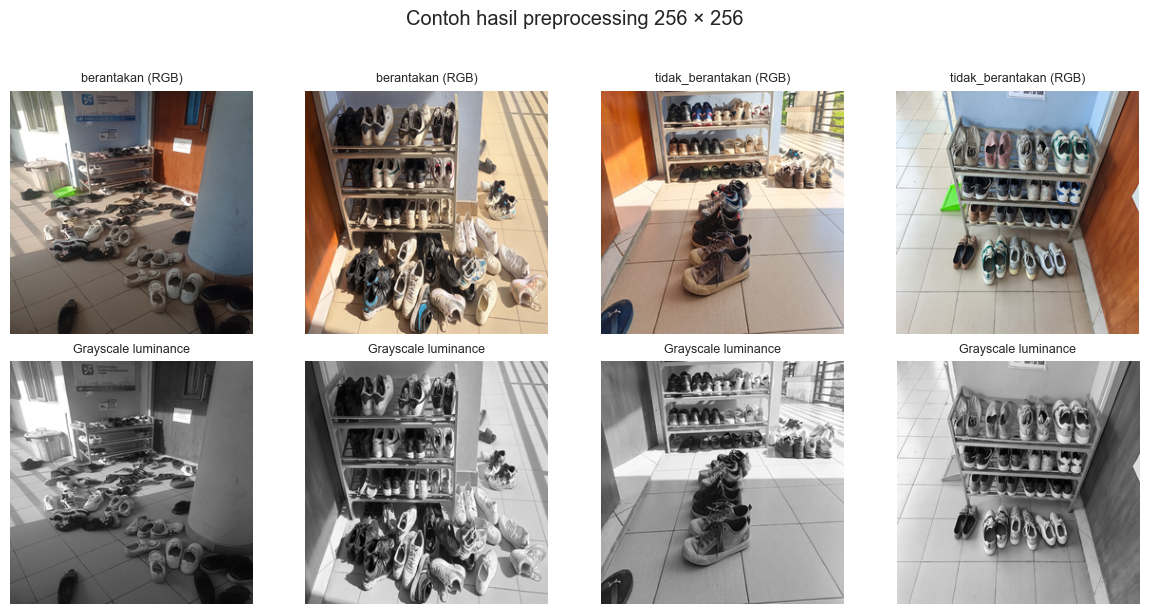

In [7]:
samples = df_images.groupby("label", sort=False).head(2).reset_index(drop=True)
fig, axes = plt.subplots(2, len(samples), figsize=(3 * len(samples), 6))
if len(samples) == 1:
    axes = np.asarray(axes).reshape(2, 1)

for index, record in samples.iterrows():
    key = str(record["path"])
    axes[0, index].imshow(rgb_cache[key])
    axes[0, index].set_title(f"{record['label']} (RGB)", fontsize=9)
    axes[1, index].imshow(gray_cache[key], cmap="gray", vmin=0, vmax=255)
    axes[1, index].set_title("Grayscale luminance", fontsize=9)
    for row in range(2):
        axes[row, index].axis("off")

fig.suptitle("Contoh hasil preprocessing 256 × 256", y=1.02)
plt.tight_layout()
plt.show()


## 5. RGB Feature Extraction

Sembilan fitur warna dihitung terpisah untuk channel R, G, dan B:

| Fitur | Rumus |
|---|---|
| Mean | $\mu = \frac{1}{MN}\sum_i\sum_j C(i,j)$ |
| Std (populasi, `ddof=0`) | $\sigma = \sqrt{\frac{1}{N}\sum_i (x_i-\mu)^2}$ |
| Skewness (tanpa koreksi sampel) | $\frac{1}{N}\sum_i\left(\frac{x_i-\mu}{\sigma}\right)^3$ |

Jika $\sigma = 0$, skewness ditetapkan 0.0 agar tidak terjadi pembagian nol. Hasil disimpan ke `outputs/features/fitur_warna.csv` dan dipakai ulang bila cache masih valid.


In [8]:
def channel_stats(channel: np.ndarray):
    mean = float(np.mean(channel))
    std = float(np.sqrt(np.mean((channel - mean) ** 2)))
    skew = 0.0 if std == 0 else float(np.mean(((channel - mean) / std) ** 3))
    return mean, std, skew


def extract_rgb_features(image: np.ndarray) -> dict:
    rgb = image.astype(np.float64)
    row = {}
    for index, channel in enumerate("RGB"):
        mean, std, skew = channel_stats(rgb[:, :, index])
        row[f"mean_{channel}"] = mean
        row[f"std_{channel}"] = std
        row[f"skew_{channel}"] = skew
    return row


def cache_is_valid(path: Path, feature_columns, records: pd.DataFrame) -> bool:
    if FORCE_RECOMPUTE or not path.exists():
        return False
    expected_columns = ["filename"] + list(feature_columns) + ["label"]
    try:
        cached = pd.read_csv(path)
    except Exception:
        return False
    if cached.columns.tolist() != expected_columns or len(cached) != len(records):
        return False
    merged = cached.merge(records[["filename", "label"]], on="filename",
                          suffixes=("_cache", "_expected"))
    if len(merged) != len(records):
        return False
    if not (merged["label_cache"] == merged["label_expected"]).all():
        return False
    return not cached[list(feature_columns)].isna().any().any()


path_rgb = FEATURE_DIR / "fitur_warna.csv"
if cache_is_valid(path_rgb, RGB_FEATURES, df_images[["filename", "label"]]):
    df_rgb = pd.read_csv(path_rgb)
    print(f"Cache dipakai: {path_rgb}")
else:
    rgb_rows = []
    for record in tqdm(valid_records, desc="Ekstraksi fitur RGB", mininterval=1.0):
        row = {"filename": record["filename"], **extract_rgb_features(rgb_cache[str(record["path"])])}
        row["label"] = record["label"]
        rgb_rows.append(row)
    df_rgb = pd.DataFrame(rgb_rows)[["filename"] + RGB_FEATURES + ["label"]]
    df_rgb.to_csv(path_rgb, index=False)
    print(f"Disimpan: {path_rgb}")

print(f"Bentuk: {df_rgb.shape}")
display(df_rgb.head())


Cache dipakai: C:\laragon\www\messy-shoe-cv\model.yolo\outputs\features\fitur_warna.csv
Bentuk: (194, 11)


,filename,mean_R,mean_G,mean_B,std_R,std_G,std_B,skew_R,skew_G,skew_B,label
0,berantakan/24-003 Berantakan 2.jpg,108.534286,101.386948,96.525131,55.241422,53.898797,52.993886,0.808198,0.820886,0.790444,berantakan
1,berantakan/24-003 Berantakan 3.jpg,149.401642,129.990875,112.172150,73.203961,70.162155,63.772413,-0.216863,-0.117219,-0.099791,berantakan
2,berantakan/24-003 berantakan.jpg,144.566132,109.828720,85.608154,70.702974,58.105508,54.109380,-0.035273,0.274176,0.661957,berantakan
3,berantakan/24-006 Berantakan 1.jpg,120.538467,112.677307,109.407394,53.310120,51.313152,50.980483,-0.500671,-0.265186,-0.182279,berantakan
4,berantakan/24-006 Berantakan 2.jpg,126.629379,119.912247,116.688019,54.220920,50.205583,48.837340,-0.772801,-0.576720,-0.425440,berantakan


## 6. GLCM Feature Extraction

GLCM dihitung dari citra grayscale dengan parameter: level 256, jarak 1, sudut 0°/45°/90°/135°, symmetric, lalu dinormalisasi sehingga jumlah elemen = 1.

| Fitur | Rumus |
|---|---|
| Energy | $\sum_i\sum_j P(i,j)^2$ (ASM, bukan akar ASM) |
| Entropy | $-\sum_i\sum_j P(i,j)\log_2 P(i,j)$ |
| Contrast | $\sum_i\sum_j (i-j)^2 P(i,j)$ |
| Correlation | $\frac{\sum_i\sum_j (i-\mu_i)(j-\mu_j)P(i,j)}{\sigma_i\sigma_j}$ |
| Homogeneity | $\sum_i\sum_j \frac{P(i,j)}{1+|i-j|}$ |

Nilai setiap fitur dihitung untuk keempat sudut lalu dirata-ratakan. Bila $\sigma_i\sigma_j = 0$ (citra seragam), correlation diberi fallback 1.0 dan didokumentasikan. Energy dan homogeneity dihitung manual, bukan lewat `graycoprops`, agar sesuai rumus jurnal.


In [9]:
GLCM_INDEX = np.arange(GLCM_LEVELS, dtype=np.float64)
GLCM_ROW = GLCM_INDEX.reshape(1, GLCM_LEVELS, 1)
GLCM_COL = GLCM_INDEX.reshape(1, 1, GLCM_LEVELS)
GLCM_CONTRAST_WEIGHT = (GLCM_INDEX[:, None] - GLCM_INDEX[None, :]) ** 2
GLCM_HOMOGENEITY_WEIGHT = 1.0 / (1.0 + np.abs(GLCM_INDEX[:, None] - GLCM_INDEX[None, :]))


def compute_glcm(gray: np.ndarray) -> np.ndarray:
    """GLCM 256 level, symmetric, belum dinormalisasi."""
    return graycomatrix(
        gray,
        distances=GLCM_DISTANCES,
        angles=GLCM_ANGLES,
        levels=GLCM_LEVELS,
        symmetric=True,
        normed=False,
    )


def glcm_features(gray: np.ndarray) -> dict:
    matrices = compute_glcm(gray)
    matrices = np.moveaxis(matrices, (2, 3), (0, 1)).reshape(-1, GLCM_LEVELS, GLCM_LEVELS)

    totals = matrices.sum(axis=(1, 2), keepdims=True).astype(np.float64)
    probabilities = np.divide(
        matrices, totals,
        out=np.zeros_like(matrices, dtype=np.float64),
        where=totals > 0,
    )

    safe = np.where(probabilities > 0, probabilities, 1.0)
    energy = np.sum(probabilities ** 2, axis=(1, 2))
    entropy = -np.sum(probabilities * np.log2(safe), axis=(1, 2))
    contrast = np.sum(probabilities * GLCM_CONTRAST_WEIGHT, axis=(1, 2))
    homogeneity = np.sum(probabilities * GLCM_HOMOGENEITY_WEIGHT, axis=(1, 2))

    marginal_i = probabilities.sum(axis=2)
    marginal_j = probabilities.sum(axis=1)
    mean_i = marginal_i @ GLCM_INDEX
    mean_j = marginal_j @ GLCM_INDEX
    delta_i = GLCM_ROW - mean_i[:, None, None]
    delta_j = GLCM_COL - mean_j[:, None, None]
    std_i = np.sqrt(np.sum(probabilities * delta_i ** 2, axis=(1, 2)))
    std_j = np.sqrt(np.sum(probabilities * delta_j ** 2, axis=(1, 2)))
    covariance = np.sum(probabilities * delta_i * delta_j, axis=(1, 2))
    denominator = std_i * std_j
    correlation = np.divide(
        covariance, denominator,
        out=np.ones_like(covariance),
        where=denominator > 0,
    )

    return {
        "energy": float(energy.mean()),
        "entropy": float(entropy.mean()),
        "contrast": float(contrast.mean()),
        "correlation": float(correlation.mean()),
        "homogeneity": float(homogeneity.mean()),
    }


In [10]:
# Sanity check satu citra terhadap graycoprops (kontras, ASM, korelasi).
sample_key = str(valid_records[0]["path"])
manual = glcm_features(gray_cache[sample_key])
reference = graycomatrix(
    gray_cache[sample_key],
    distances=[1], angles=[0], levels=GLCM_LEVELS, symmetric=True, normed=True,
)
comparison = pd.DataFrame({
    "manual (jurnal)": [manual["contrast"], manual["energy"], manual["correlation"]],
    "graycoprops": [
        graycoprops(reference, "contrast")[0, 0],
        graycoprops(reference, "ASM")[0, 0],
        graycoprops(reference, "correlation")[0, 0],
    ],
}, index=["contrast", "energy (=ASM)", "correlation"])
display(comparison.round(6))
print("Homogeneity sengaja tidak dibandingkan: scikit-image memakai (i-j)^2, jurnal memakai |i-j|.")


,manual (jurnal),graycoprops
contrast,330.321012,205.694792
energy (=ASM),0.001131,0.001236
correlation,0.941826,0.963756


Homogeneity sengaja tidak dibandingkan: scikit-image memakai (i-j)^2, jurnal memakai |i-j|.


In [11]:
path_glcm = FEATURE_DIR / "fitur_glcm.csv"
if cache_is_valid(path_glcm, GLCM_FEATURES, df_images[["filename", "label"]]):
    df_glcm = pd.read_csv(path_glcm)
    print(f"Cache dipakai: {path_glcm}")
else:
    glcm_rows = []
    for record in tqdm(valid_records, desc="Ekstraksi fitur GLCM", mininterval=1.0):
        row = {"filename": record["filename"], **glcm_features(gray_cache[str(record["path"])])}
        row["label"] = record["label"]
        glcm_rows.append(row)
    df_glcm = pd.DataFrame(glcm_rows)[["filename"] + GLCM_FEATURES + ["label"]]
    df_glcm.to_csv(path_glcm, index=False)
    print(f"Disimpan: {path_glcm}")

print(f"Bentuk: {df_glcm.shape}")
display(df_glcm.head())


Cache dipakai: C:\laragon\www\messy-shoe-cv\model.yolo\outputs\features\fitur_glcm.csv
Bentuk: (194, 7)


,filename,energy,entropy,contrast,correlation,homogeneity,label
0,berantakan/24-003 Berantakan 2.jpg,0.001131,12.032952,330.321012,0.941826,0.390360,berantakan
1,berantakan/24-003 Berantakan 3.jpg,0.000250,13.443955,783.837610,0.919210,0.275470,berantakan
2,berantakan/24-003 berantakan.jpg,0.000280,13.160252,632.811217,0.907353,0.287342,berantakan
3,berantakan/24-006 Berantakan 1.jpg,0.000651,12.386440,410.640127,0.922358,0.334862,berantakan
4,berantakan/24-006 Berantakan 2.jpg,0.001014,11.479518,201.984589,0.961356,0.419820,berantakan


## 7. HOG Feature Extraction

HOG dihitung dengan `skimage.feature.hog`: 9 orientasi, cell 8 × 8, block 2 × 2, normalisasi L2-Hys. Vektor HOG penuh memiliki ribuan dimensi, sehingga diagregasi menjadi 9 fitur:

1. Vektor HOG di-reshape menjadi matriks `(jumlah_block, 9)`.
2. Nilai setiap bin orientasi dirata-ratakan lintas block.
3. Hasil dinormalisasi L1 sehingga jumlah kesembilan bin = 1.

Agregasi ini konsisten untuk semua citra karena jumlah cell dan block selalu sama untuk input 256 × 256. Sembilan nilai pertama vektor HOG **tidak** diambil langsung karena semuanya berasal dari satu block saja.


In [12]:
def hog_features(gray: np.ndarray) -> dict:
    vector = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True,
    )
    bins = vector.reshape(-1, 9).mean(axis=0)
    total = bins.sum()
    bins = bins / total if total > 0 else np.full(9, 1.0 / 9.0)
    return dict(zip(HOG_FEATURES, bins.astype(float)))


path_hog = FEATURE_DIR / "fitur_hog.csv"
if cache_is_valid(path_hog, HOG_FEATURES, df_images[["filename", "label"]]):
    df_hog = pd.read_csv(path_hog)
    print(f"Cache dipakai: {path_hog}")
else:
    hog_rows = []
    for record in tqdm(valid_records, desc="Ekstraksi fitur HOG", mininterval=1.0):
        row = {"filename": record["filename"], **hog_features(gray_cache[str(record["path"])])}
        row["label"] = record["label"]
        hog_rows.append(row)
    df_hog = pd.DataFrame(hog_rows)[["filename"] + HOG_FEATURES + ["label"]]
    df_hog.to_csv(path_hog, index=False)
    print(f"Disimpan: {path_hog}")

print(f"Bentuk: {df_hog.shape}")
display(df_hog.head())


Cache dipakai: C:\laragon\www\messy-shoe-cv\model.yolo\outputs\features\fitur_hog.csv
Bentuk: (194, 11)


,filename,hog_bin_01,hog_bin_02,hog_bin_03,hog_bin_04,hog_bin_05,hog_bin_06,hog_bin_07,hog_bin_08,hog_bin_09,label
0,berantakan/24-003 Berantakan 2.jpg,0.132127,0.090764,0.110833,0.123585,0.146968,0.105684,0.110864,0.092225,0.086950,berantakan
1,berantakan/24-003 Berantakan 3.jpg,0.152511,0.109601,0.084790,0.069627,0.111891,0.085787,0.094410,0.141121,0.150261,berantakan
2,berantakan/24-003 berantakan.jpg,0.139191,0.133148,0.130992,0.074957,0.082742,0.092657,0.125330,0.114561,0.106421,berantakan
3,berantakan/24-006 Berantakan 1.jpg,0.165709,0.124722,0.128211,0.095171,0.089555,0.064195,0.097028,0.113200,0.122209,berantakan
4,berantakan/24-006 Berantakan 2.jpg,0.182031,0.101427,0.087884,0.068885,0.109235,0.085915,0.104881,0.122894,0.136848,berantakan


## 8. LBP Feature Extraction

Local Binary Pattern memakai `radius=1`, `n_points=8`, `method="uniform"`. Pada konfigurasi ini kode LBP uniform bernilai 0–9 (9 pola seragam + 1 pola non-seragam), sehingga histogram memiliki 10 bin. Histogram dinormalisasi agar jumlahnya 1 sehingga dapat dibandingkan antar citra.


In [13]:
def lbp_features(gray: np.ndarray) -> dict:
    codes = local_binary_pattern(gray, P=8, R=1, method="uniform")
    histogram, _ = np.histogram(codes, bins=np.arange(0, 11), range=(0, 10))
    histogram = histogram.astype(np.float64)
    total = histogram.sum()
    histogram = histogram / total if total > 0 else np.full(10, 0.1)
    return dict(zip(LBP_FEATURES, histogram))


path_lbp = FEATURE_DIR / "fitur_lbp.csv"
if cache_is_valid(path_lbp, LBP_FEATURES, df_images[["filename", "label"]]):
    df_lbp = pd.read_csv(path_lbp)
    print(f"Cache dipakai: {path_lbp}")
else:
    lbp_rows = []
    for record in tqdm(valid_records, desc="Ekstraksi fitur LBP", mininterval=1.0):
        row = {"filename": record["filename"], **lbp_features(gray_cache[str(record["path"])])}
        row["label"] = record["label"]
        lbp_rows.append(row)
    df_lbp = pd.DataFrame(lbp_rows)[["filename"] + LBP_FEATURES + ["label"]]
    df_lbp.to_csv(path_lbp, index=False)
    print(f"Disimpan: {path_lbp}")

print(f"Bentuk: {df_lbp.shape}")
display(df_lbp.head())


Cache dipakai: C:\laragon\www\messy-shoe-cv\model.yolo\outputs\features\fitur_lbp.csv
Bentuk: (194, 12)


,filename,lbp_bin_00,lbp_bin_01,lbp_bin_02,lbp_bin_03,lbp_bin_04,lbp_bin_05,lbp_bin_06,lbp_bin_07,lbp_bin_08,lbp_bin_09,label
0,berantakan/24-003 Berantakan 2.jpg,0.043411,0.082214,0.034317,0.092239,0.177628,0.135330,0.063629,0.102814,0.138535,0.129883,berantakan
1,berantakan/24-003 Berantakan 3.jpg,0.051407,0.095093,0.041901,0.086823,0.212494,0.111923,0.061462,0.100372,0.104187,0.134338,berantakan
2,berantakan/24-003 berantakan.jpg,0.064056,0.079956,0.043045,0.095093,0.197632,0.117584,0.061325,0.089905,0.108490,0.142914,berantakan
3,berantakan/24-006 Berantakan 1.jpg,0.047028,0.084259,0.035980,0.095200,0.221558,0.127960,0.063766,0.094284,0.106216,0.123749,berantakan
4,berantakan/24-006 Berantakan 2.jpg,0.034149,0.078583,0.029236,0.098846,0.205048,0.158630,0.070587,0.096390,0.113144,0.115387,berantakan


## 9. YOLO Object Detection (Mode 2, opsional)

Dataset ini belum memiliki anotasi bounding box, sehingga YOLO **tidak dilatih** di sini. Notebook hanya memakai model YOLO yang sudah ada dan memiliki kelas `shoe`.

Karena model COCO standar tidak memiliki kelas `shoe`, `YOLO_WEIGHTS` sengaja dibiarkan `None`. Bila Anda sudah melatih/fine-tuning YOLO dengan kelas `shoe`, isi path bobotnya di sel konfigurasi lalu jalankan ulang notebook.

Perilaku saat YOLO tidak siap:

- Tidak ada file CSV YOLO kosong yang dibuat.
- Seluruh proses baseline (RGB + GLCM + HOG + LBP) tetap berjalan.
- Eksperimen E4 dan E6 ditandai *skipped* pada tabel ablation.


In [14]:
yolo_skip_reasons = []

if not ULTRALYTICS_AVAILABLE:
    yolo_skip_reasons.append(
        "Paket 'ultralytics' tidak terpasang (set INSTALL_DEPENDENCIES=True dan INSTALL_YOLO=True)."
    )
if YOLO_WEIGHTS is None:
    yolo_skip_reasons.append(
        "YOLO_WEIGHTS belum diisi. Model COCO tidak memiliki kelas 'shoe', "
        "jadi bobot hasil fine-tuning kelas 'shoe' wajib disediakan."
    )
elif not Path(YOLO_WEIGHTS).exists():
    yolo_skip_reasons.append(f"File bobot tidak ditemukan: {YOLO_WEIGHTS}")

YOLO_READY = len(yolo_skip_reasons) == 0

print("Status YOLO:", "SIAP" if YOLO_READY else "DILEWATI")
for reason in yolo_skip_reasons:
    print(" -", reason)


Status YOLO: DILEWATI
 - Paket 'ultralytics' tidak terpasang (set INSTALL_DEPENDENCIES=True dan INSTALL_YOLO=True).
 - YOLO_WEIGHTS belum diisi. Model COCO tidak memiliki kelas 'shoe', jadi bobot hasil fine-tuning kelas 'shoe' wajib disediakan.


In [15]:
yolo_detections = {}
yolo_status = "skipped"

if YOLO_READY:
    yolo_model = YOLO(YOLO_WEIGHTS)
    raw_names = yolo_model.names
    if isinstance(raw_names, dict):
        model_names = {int(key): str(value) for key, value in raw_names.items()}
    else:
        model_names = {index: str(value) for index, value in enumerate(raw_names)}
    shoe_ids = [key for key, value in model_names.items()
                if value.lower() == YOLO_CLASS_NAME.lower()]

    if not shoe_ids:
        YOLO_READY = False
        print(f"Model tidak memiliki kelas '{YOLO_CLASS_NAME}'. "
              f"Kelas tersedia: {sorted(model_names.values())[:20]}")
        print("Bagian YOLO dilewati; baseline tetap berjalan.")
    else:
        cache_path = FEATURE_DIR / "yolo_detections.json"

        if cache_path.exists() and not FORCE_RECOMPUTE:
            with open(cache_path, encoding="utf-8") as handle:
                cached = json.load(handle)
            if set(cached) == set(df_images["filename"]):
                yolo_detections = cached
                yolo_status = "cache"
                print(f"Cache deteksi dipakai: {cache_path}")

        if not yolo_detections:
            for record in tqdm(valid_records, desc="Deteksi objek YOLO", mininterval=1.0):
                try:
                    result = yolo_model.predict(
                        source=str(record["path"]),
                        conf=YOLO_CONF,
                        iou=YOLO_IOU,
                        imgsz=YOLO_IMG_SIZE,
                        verbose=False,
                    )[0]
                    boxes = result.boxes
                    if boxes is None or len(boxes) == 0:
                        entry = {"status": "no_detection", "boxes": []}
                    else:
                        xyxy = boxes.xyxy.cpu().numpy()
                        confidence = boxes.conf.cpu().numpy()
                        classes = boxes.cls.cpu().numpy().astype(int)
                        mask = np.isin(classes, shoe_ids)
                        entry = {
                            "status": "ok" if mask.any() else "no_detection",
                            "boxes": [
                                [float(value) for value in box] + [float(score)]
                                for box, score in zip(xyxy[mask], confidence[mask])
                            ],
                        }
                    entry["width"] = int(record["width"])
                    entry["height"] = int(record["height"])
                    yolo_detections[record["filename"]] = entry
                except Exception as error:
                    yolo_detections[record["filename"]] = {
                        "status": "error",
                        "boxes": [],
                        "width": int(record["width"]),
                        "height": int(record["height"]),
                        "error": str(error),
                    }

            with open(cache_path, "w", encoding="utf-8") as handle:
                json.dump(yolo_detections, handle)
            yolo_status = "computed"
            print(f"Disimpan: {cache_path}")

        status_counts = pd.Series(
            [entry["status"] for entry in yolo_detections.values()]
        ).value_counts()
        display(status_counts.rename("jumlah citra").to_frame())
        print("Detection failure TIDAK dianggap nol sepatu; status disimpan sebagai metadata.")


In [16]:
if YOLO_READY and yolo_detections:
    sample_names = [name for name, entry in yolo_detections.items()
                    if entry["status"] == "ok"][:4]
    if sample_names:
        fig, axes = plt.subplots(1, len(sample_names), figsize=(4 * len(sample_names), 4))
        axes = np.atleast_1d(axes)
        for ax, filename in zip(axes, sample_names):
            record = df_images[df_images["filename"] == filename].iloc[0]
            ax.imshow(rgb_cache[str(record["path"])])
            for x1, y1, x2, y2, confidence in yolo_detections[filename]["boxes"]:
                ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                           fill=False, edgecolor="lime", linewidth=2))
                ax.text(x1, y1 - 5, f"{confidence:.2f}", color="lime", fontsize=8)
            ax.set_title(filename, fontsize=8)
            ax.axis("off")
        fig.suptitle("Contoh deteksi bounding box sepatu", y=1.02)
        plt.tight_layout()
        plt.show()
else:
    print("Visualisasi deteksi YOLO dilewati karena Mode 2 belum aktif.")


Visualisasi deteksi YOLO dilewati karena Mode 2 belum aktif.


## 10. YOLO Feature Extraction

### Geometric features (8)

| Fitur | Definisi |
|---|---|
| `shoe_count` | jumlah bounding box sepatu valid |
| `mean_bbox_area`, `std_bbox_area` | luas bbox / luas gambar |
| `mean_bbox_aspect_ratio`, `std_bbox_aspect_ratio` | lebar / tinggi bbox |
| `mean_bbox_width`, `mean_bbox_height` | dimensi bbox relatif terhadap gambar |
| `mean_detection_confidence` | rata-rata confidence deteksi |

### Spatial features (8)

Koordinat pusat dinormalisasi ke `[0, 1]`, jarak dinormalisasi terhadap diagonal unit square ($\sqrt{2}$).

| Fitur | Definisi |
|---|---|
| `mean_nearest_neighbor_distance`, `std_nearest_neighbor_distance` | jarak pusat ke pusat terdekat |
| `mean_pairwise_distance` | rata-rata jarak semua pasangan pusat |
| `horizontal_alignment_score` | $1/(1+\sigma_y)$: mendekati 1 bila pusat sejajar horizontal |
| `vertical_alignment_score` | $1/(1+\sigma_x)$: mendekati 1 bila pusat sejajar vertikal |
| `spatial_dispersion_x`, `spatial_dispersion_y` | simpangan baku posisi pusat |
| `bbox_overlap_ratio` | proporsi pasangan bbox dengan IoU > 0 |

Penanganan nilai tidak terdefinisi:

- Tidak ada deteksi → seluruh fitur geometris/spasial `NaN`, status `no_detection`.
- Satu deteksi → `std_*` = 0.0 dan dispersion = 0.0; jarak/alignment/overlap `NaN` karena tidak ada pasangan.
- Detection failure tidak diisi nol dan tidak dipakai sebagai data latih hybrid.


In [17]:
def geometric_features(boxes: np.ndarray, width: int, height: int) -> dict:
    if len(boxes) == 0:
        return {name: np.nan for name in YOLO_GEO_FEATURES}

    x1, y1, x2, y2 = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    box_width = (x2 - x1) / width
    box_height = (y2 - y1) / height
    area = box_width * box_height
    aspect = box_width / np.maximum(box_height, 1e-12)
    confidence = boxes[:, 4]

    def safe_std(values):
        return float(np.std(values, ddof=0)) if len(values) > 1 else 0.0

    return {
        "shoe_count": int(len(boxes)),
        "mean_bbox_area": float(area.mean()),
        "std_bbox_area": safe_std(area),
        "mean_bbox_aspect_ratio": float(aspect.mean()),
        "std_bbox_aspect_ratio": safe_std(aspect),
        "mean_bbox_width": float(box_width.mean()),
        "mean_bbox_height": float(box_height.mean()),
        "mean_detection_confidence": float(confidence.mean()),
    }


def iou_matrix(boxes: np.ndarray) -> np.ndarray:
    x1, y1, x2, y2 = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    areas = np.maximum(x2 - x1, 0) * np.maximum(y2 - y1, 0)
    inter_x1 = np.maximum(x1[:, None], x1[None, :])
    inter_y1 = np.maximum(y1[:, None], y1[None, :])
    inter_x2 = np.minimum(x2[:, None], x2[None, :])
    inter_y2 = np.minimum(y2[:, None], y2[None, :])
    inter = np.maximum(inter_x2 - inter_x1, 0) * np.maximum(inter_y2 - inter_y1, 0)
    union = areas[:, None] + areas[None, :] - inter
    return np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)


def spatial_features(boxes: np.ndarray, width: int, height: int) -> dict:
    names = YOLO_SPATIAL_FEATURES
    if len(boxes) == 0:
        return {name: np.nan for name in names}

    centers_x = ((boxes[:, 0] + boxes[:, 2]) / 2) / width
    centers_y = ((boxes[:, 1] + boxes[:, 3]) / 2) / height

    if len(boxes) == 1:
        return {
            "mean_nearest_neighbor_distance": np.nan,
            "std_nearest_neighbor_distance": np.nan,
            "mean_pairwise_distance": np.nan,
            "horizontal_alignment_score": np.nan,
            "vertical_alignment_score": np.nan,
            "spatial_dispersion_x": 0.0,
            "spatial_dispersion_y": 0.0,
            "bbox_overlap_ratio": np.nan,
        }

    coordinates = np.column_stack([centers_x, centers_y])
    distance_matrix = np.sqrt(((coordinates[:, None, :] - coordinates[None, :, :]) ** 2).sum(axis=2))
    np.fill_diagonal(distance_matrix, np.inf)
    nearest = distance_matrix.min(axis=1) / np.sqrt(2.0)
    pairwise = distance_matrix[np.triu_indices(len(boxes), k=1)] / np.sqrt(2.0)

    overlap = iou_matrix(boxes)
    upper = overlap[np.triu_indices(len(boxes), k=1)]

    return {
        "mean_nearest_neighbor_distance": float(nearest.mean()),
        "std_nearest_neighbor_distance": float(nearest.std(ddof=0)),
        "mean_pairwise_distance": float(pairwise.mean()),
        "horizontal_alignment_score": float(1.0 / (1.0 + centers_y.std(ddof=0))),
        "vertical_alignment_score": float(1.0 / (1.0 + centers_x.std(ddof=0))),
        "spatial_dispersion_x": float(centers_x.std(ddof=0)),
        "spatial_dispersion_y": float(centers_y.std(ddof=0)),
        "bbox_overlap_ratio": float((upper > 0).mean()),
    }


In [18]:
df_yolo_geo = None
df_yolo_spatial = None
df_yolo = None

if YOLO_READY and yolo_detections:
    geo_rows, spatial_rows = [], []
    for record in tqdm(valid_records, desc="Ekstraksi fitur YOLO", mininterval=1.0):
        entry = yolo_detections[record["filename"]]
        boxes = np.asarray(entry["boxes"], dtype=np.float64).reshape(-1, 5)
        row = {"filename": record["filename"]}
        row.update(geometric_features(boxes, entry["width"], entry["height"]))
        row["detection_status"] = entry["status"]
        row["label"] = record["label"]
        geo_rows.append(row)

        spatial_row = {"filename": record["filename"]}
        spatial_row.update(spatial_features(boxes, entry["width"], entry["height"]))
        spatial_row["detection_status"] = entry["status"]
        spatial_row["label"] = record["label"]
        spatial_rows.append(spatial_row)

    df_yolo_geo = pd.DataFrame(geo_rows)[["filename"] + YOLO_GEO_FEATURES + ["detection_status", "label"]]
    df_yolo_spatial = pd.DataFrame(spatial_rows)[
        ["filename"] + YOLO_SPATIAL_FEATURES + ["detection_status", "label"]
    ]
    df_yolo = df_yolo_geo.merge(
        df_yolo_spatial[["filename"] + YOLO_SPATIAL_FEATURES],
        on="filename", how="inner",
    )[["filename"] + YOLO_FEATURES + ["detection_status", "label"]]

    df_yolo_geo.to_csv(FEATURE_DIR / "fitur_yolo_geometric.csv", index=False)
    df_yolo_spatial.to_csv(FEATURE_DIR / "fitur_yolo_spatial.csv", index=False)
    df_yolo.to_csv(FEATURE_DIR / "fitur_yolo.csv", index=False)
    print(f"Disimpan 3 CSV YOLO di {FEATURE_DIR}")
    display(df_yolo.head())
else:
    print("Ekstraksi fitur YOLO dilewati (Mode 1 baseline). Tidak ada CSV YOLO yang dibuat.")


Ekstraksi fitur YOLO dilewati (Mode 1 baseline). Tidak ada CSV YOLO yang dibuat.


## 11. Feature Integration

Fitur digabung **berdasarkan `filename`**, bukan urutan baris. `filename` hanya identifier dan tidak masuk ke matriks prediktor. `detection_status` disimpan sebagai metadata pada file hybrid dan juga tidak dipakai sebagai fitur.

Output yang dibuat:

- `fitur_lengkap.csv` — 33 fitur non-YOLO.
- `fitur_hybrid.csv` — 49 fitur bila YOLO siap dan deteksi berhasil.
- `hasil_ekstraksi_fitur.xlsx` — sheet RGB, GLCM, HOG, LBP, dan YOLO/Hybrid bila tersedia.


In [19]:
df_base = (
    df_rgb
    .merge(df_glcm, on=["filename", "label"], how="inner")
    .merge(df_hog, on=["filename", "label"], how="inner")
    .merge(df_lbp, on=["filename", "label"], how="inner")
)[["filename"] + BASE_FEATURES + ["label"]]

if len(df_base) != len(df_images):
    raise ValueError(
        f"Penggabungan kehilangan baris: {len(df_base)} dari {len(df_images)} citra."
    )
if df_base["filename"].duplicated().any():
    raise ValueError("Terdapat filename duplikat setelah penggabungan.")

df_base.to_csv(FEATURE_DIR / "fitur_lengkap.csv", index=False)
print(f"fitur_lengkap.csv: {df_base.shape}")
display(df_base.head())


fitur_lengkap.csv: (194, 35)


,filename,mean_R,mean_G,mean_B,std_R,std_G,std_B,skew_R,skew_G,skew_B,energy,entropy,contrast,correlation,homogeneity,hog_bin_01,hog_bin_02,hog_bin_03,hog_bin_04,hog_bin_05,hog_bin_06,hog_bin_07,hog_bin_08,hog_bin_09,lbp_bin_00,lbp_bin_01,lbp_bin_02,lbp_bin_03,lbp_bin_04,lbp_bin_05,lbp_bin_06,lbp_bin_07,lbp_bin_08,lbp_bin_09,label
0,berantakan/24-003 Berantakan 2.jpg,108.534286,101.386948,96.525131,55.241422,53.898797,52.993886,0.808198,0.820886,0.790444,0.001131,12.032952,330.321012,0.941826,0.390360,0.132127,0.090764,0.110833,0.123585,0.146968,0.105684,0.110864,0.092225,0.086950,0.043411,0.082214,0.034317,0.092239,0.177628,0.135330,0.063629,0.102814,0.138535,0.129883,berantakan
1,berantakan/24-003 Berantakan 3.jpg,149.401642,129.990875,112.172150,73.203961,70.162155,63.772413,-0.216863,-0.117219,-0.099791,0.000250,13.443955,783.837610,0.919210,0.275470,0.152511,0.109601,0.084790,0.069627,0.111891,0.085787,0.094410,0.141121,0.150261,0.051407,0.095093,0.041901,0.086823,0.212494,0.111923,0.061462,0.100372,0.104187,0.134338,berantakan
2,berantakan/24-003 berantakan.jpg,144.566132,109.828720,85.608154,70.702974,58.105508,54.109380,-0.035273,0.274176,0.661957,0.000280,13.160252,632.811217,0.907353,0.287342,0.139191,0.133148,0.130992,0.074957,0.082742,0.092657,0.125330,0.114561,0.106421,0.064056,0.079956,0.043045,0.095093,0.197632,0.117584,0.061325,0.089905,0.108490,0.142914,berantakan
3,berantakan/24-006 Berantakan 1.jpg,120.538467,112.677307,109.407394,53.310120,51.313152,50.980483,-0.500671,-0.265186,-0.182279,0.000651,12.386440,410.640127,0.922358,0.334862,0.165709,0.124722,0.128211,0.095171,0.089555,0.064195,0.097028,0.113200,0.122209,0.047028,0.084259,0.035980,0.095200,0.221558,0.127960,0.063766,0.094284,0.106216,0.123749,berantakan
4,berantakan/24-006 Berantakan 2.jpg,126.629379,119.912247,116.688019,54.220920,50.205583,48.837340,-0.772801,-0.576720,-0.425440,0.001014,11.479518,201.984589,0.961356,0.419820,0.182031,0.101427,0.087884,0.068885,0.109235,0.085915,0.104881,0.122894,0.136848,0.034149,0.078583,0.029236,0.098846,0.205048,0.158630,0.070587,0.096390,0.113144,0.115387,berantakan


In [20]:
df_hybrid = None
df_model_data = df_base

if df_yolo is not None:
    merged = df_base.merge(df_yolo, on=["filename", "label"], how="inner", suffixes=("", "_yolo"))
    failed = merged["detection_status"] != "ok"
    partial = (~failed) & merged[YOLO_FEATURES].isna().any(axis=1)

    print(f"Detection failure (no_detection/error): {int(failed.sum())} citra")
    print(f"Deteksi valid namun fitur spasial tidak terdefinisi (objek < 2): {int(partial.sum())} citra")
    if failed.any():
        display(merged.loc[failed, ["filename", "detection_status", "label"]])

    keep = ~(failed | partial)
    df_hybrid = merged.loc[keep, ["filename"] + HYBRID_FEATURES + ["detection_status", "label"]]
    df_hybrid = df_hybrid.reset_index(drop=True)

    if df_hybrid.empty:
        print("Tidak ada citra dengan deteksi valid; fitur_hybrid.csv tidak dibuat.")
        df_hybrid = None
    else:
        df_hybrid.to_csv(FEATURE_DIR / "fitur_hybrid.csv", index=False)
        print(f"fitur_hybrid.csv: {df_hybrid.shape}")
        display(df_hybrid.head())
        df_model_data = df_hybrid
        print(f"Mode 2: {len(df_model_data)} citra dipakai pada SEMUA eksperimen "
              "agar pembagian train/test tetap identik.")
else:
    print("fitur_hybrid.csv tidak dibuat karena fitur YOLO tidak tersedia.")


fitur_hybrid.csv tidak dibuat karena fitur YOLO tidak tersedia.

In [21]:
excel_path = FEATURE_DIR / "hasil_ekstraksi_fitur.xlsx"
sheets = {
    "RGB": df_rgb,
    "GLCM": df_glcm,
    "HOG": df_hog,
    "LBP": df_lbp,
}
if df_yolo_geo is not None:
    sheets["YOLO_Geometric"] = df_yolo_geo
    sheets["YOLO_Spatial"] = df_yolo_spatial
if df_hybrid is not None:
    sheets["Hybrid"] = df_hybrid

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    for sheet_name, frame in sheets.items():
        frame.to_excel(writer, sheet_name=sheet_name, index=False)

print(f"Excel disimpan: {excel_path}")
print("Sheet:", ", ".join(sheets))


Excel disimpan: C:\laragon\www\messy-shoe-cv\model.yolo\outputs\features\hasil_ekstraksi_fitur.xlsx
Sheet: RGB, GLCM, HOG, LBP


## 12. Exploratory Data Analysis

EDA memeriksa keseimbangan kelas, missing values, duplikat baris fitur, statistik deskriptif, sebaran fitur per kelas, dan korelasi antarfitur. Fitur **tidak dihapus** hanya karena korelasi tinggi; keputusan seleksi fitur dilakukan lewat eksperimen pada Section 15.


In [22]:
print("Distribusi kelas:")
display(df_base["label"].value_counts().reindex(CLASS_LABELS, fill_value=0).rename("jumlah").to_frame())

print("Proporsi kelas:")
display((df_base["label"].value_counts() / len(df_base)).round(3).rename("proporsi").to_frame())


Distribusi kelas:


,jumlah
label,
berantakan,97
tidak_berantakan,97


Proporsi kelas:


,proporsi
label,
berantakan,0.5
tidak_berantakan,0.5


In [23]:
missing = df_base[BASE_FEATURES].isna().sum().rename("missing")
print("Missing value pada 33 fitur baseline:")
display(missing.to_frame())
if missing.sum() > 0:
    raise ValueError("Terdapat NaN pada fitur baseline; periksa kembali ekstraksi fitur.")

duplicate_rows = int(df_base[BASE_FEATURES].duplicated(keep=False).sum())
print(f"Baris dengan nilai fitur identik: {duplicate_rows} (duplikat tidak dihapus otomatis).")


Missing value pada 33 fitur baseline:


,missing
mean_R,0
mean_G,0
mean_B,0
std_R,0
std_G,0
std_B,0
skew_R,0
skew_G,0
skew_B,0
energy,0


Baris dengan nilai fitur identik: 21 (duplikat tidak dihapus otomatis).


In [24]:
print("Statistik deskriptif fitur baseline:")
display(df_base[BASE_FEATURES].describe().T.round(4))


Statistik deskriptif fitur baseline:


,count,mean,std,min,25%,50%,75%,max
mean_R,194.0,136.5113,18.7600,73.9708,124.7129,138.7269,148.2228,176.5669
mean_G,194.0,126.6826,17.4358,65.1019,116.2297,128.7501,137.2460,168.2195
mean_B,194.0,118.9977,18.2013,64.3856,106.9784,117.5355,131.5461,164.5273
std_R,194.0,58.1282,10.3803,33.6115,51.5415,58.3080,66.1587,88.7745
std_G,194.0,59.8638,7.5811,33.2879,53.7478,60.2230,65.3103,84.6178
std_B,194.0,60.9115,7.5342,30.7756,55.9497,61.2555,66.1934,79.7244
skew_R,194.0,-0.2893,0.4742,-1.4970,-0.6114,-0.2828,0.0106,0.9089
skew_G,194.0,-0.0981,0.4047,-1.2576,-0.3660,-0.1367,0.1867,0.8814
skew_B,194.0,-0.0412,0.4048,-1.1176,-0.3342,-0.0936,0.2613,0.8737
energy,194.0,0.0011,0.0034,0.0002,0.0004,0.0006,0.0009,0.0348


In [25]:
print("Rata-rata fitur per kelas:")
display(df_base.groupby("label")[BASE_FEATURES].mean().reindex(CLASS_LABELS).T.round(4))


Rata-rata fitur per kelas:


label,berantakan,tidak_berantakan
mean_R,136.8123,136.2104
mean_G,126.7639,126.6012
mean_B,117.9478,120.0476
std_R,59.2289,57.0275
std_G,59.7536,59.9739
std_B,59.7017,62.1213
skew_R,-0.3177,-0.2610
skew_G,-0.1316,-0.0646
skew_B,-0.0370,-0.0453
energy,0.0015,0.0007


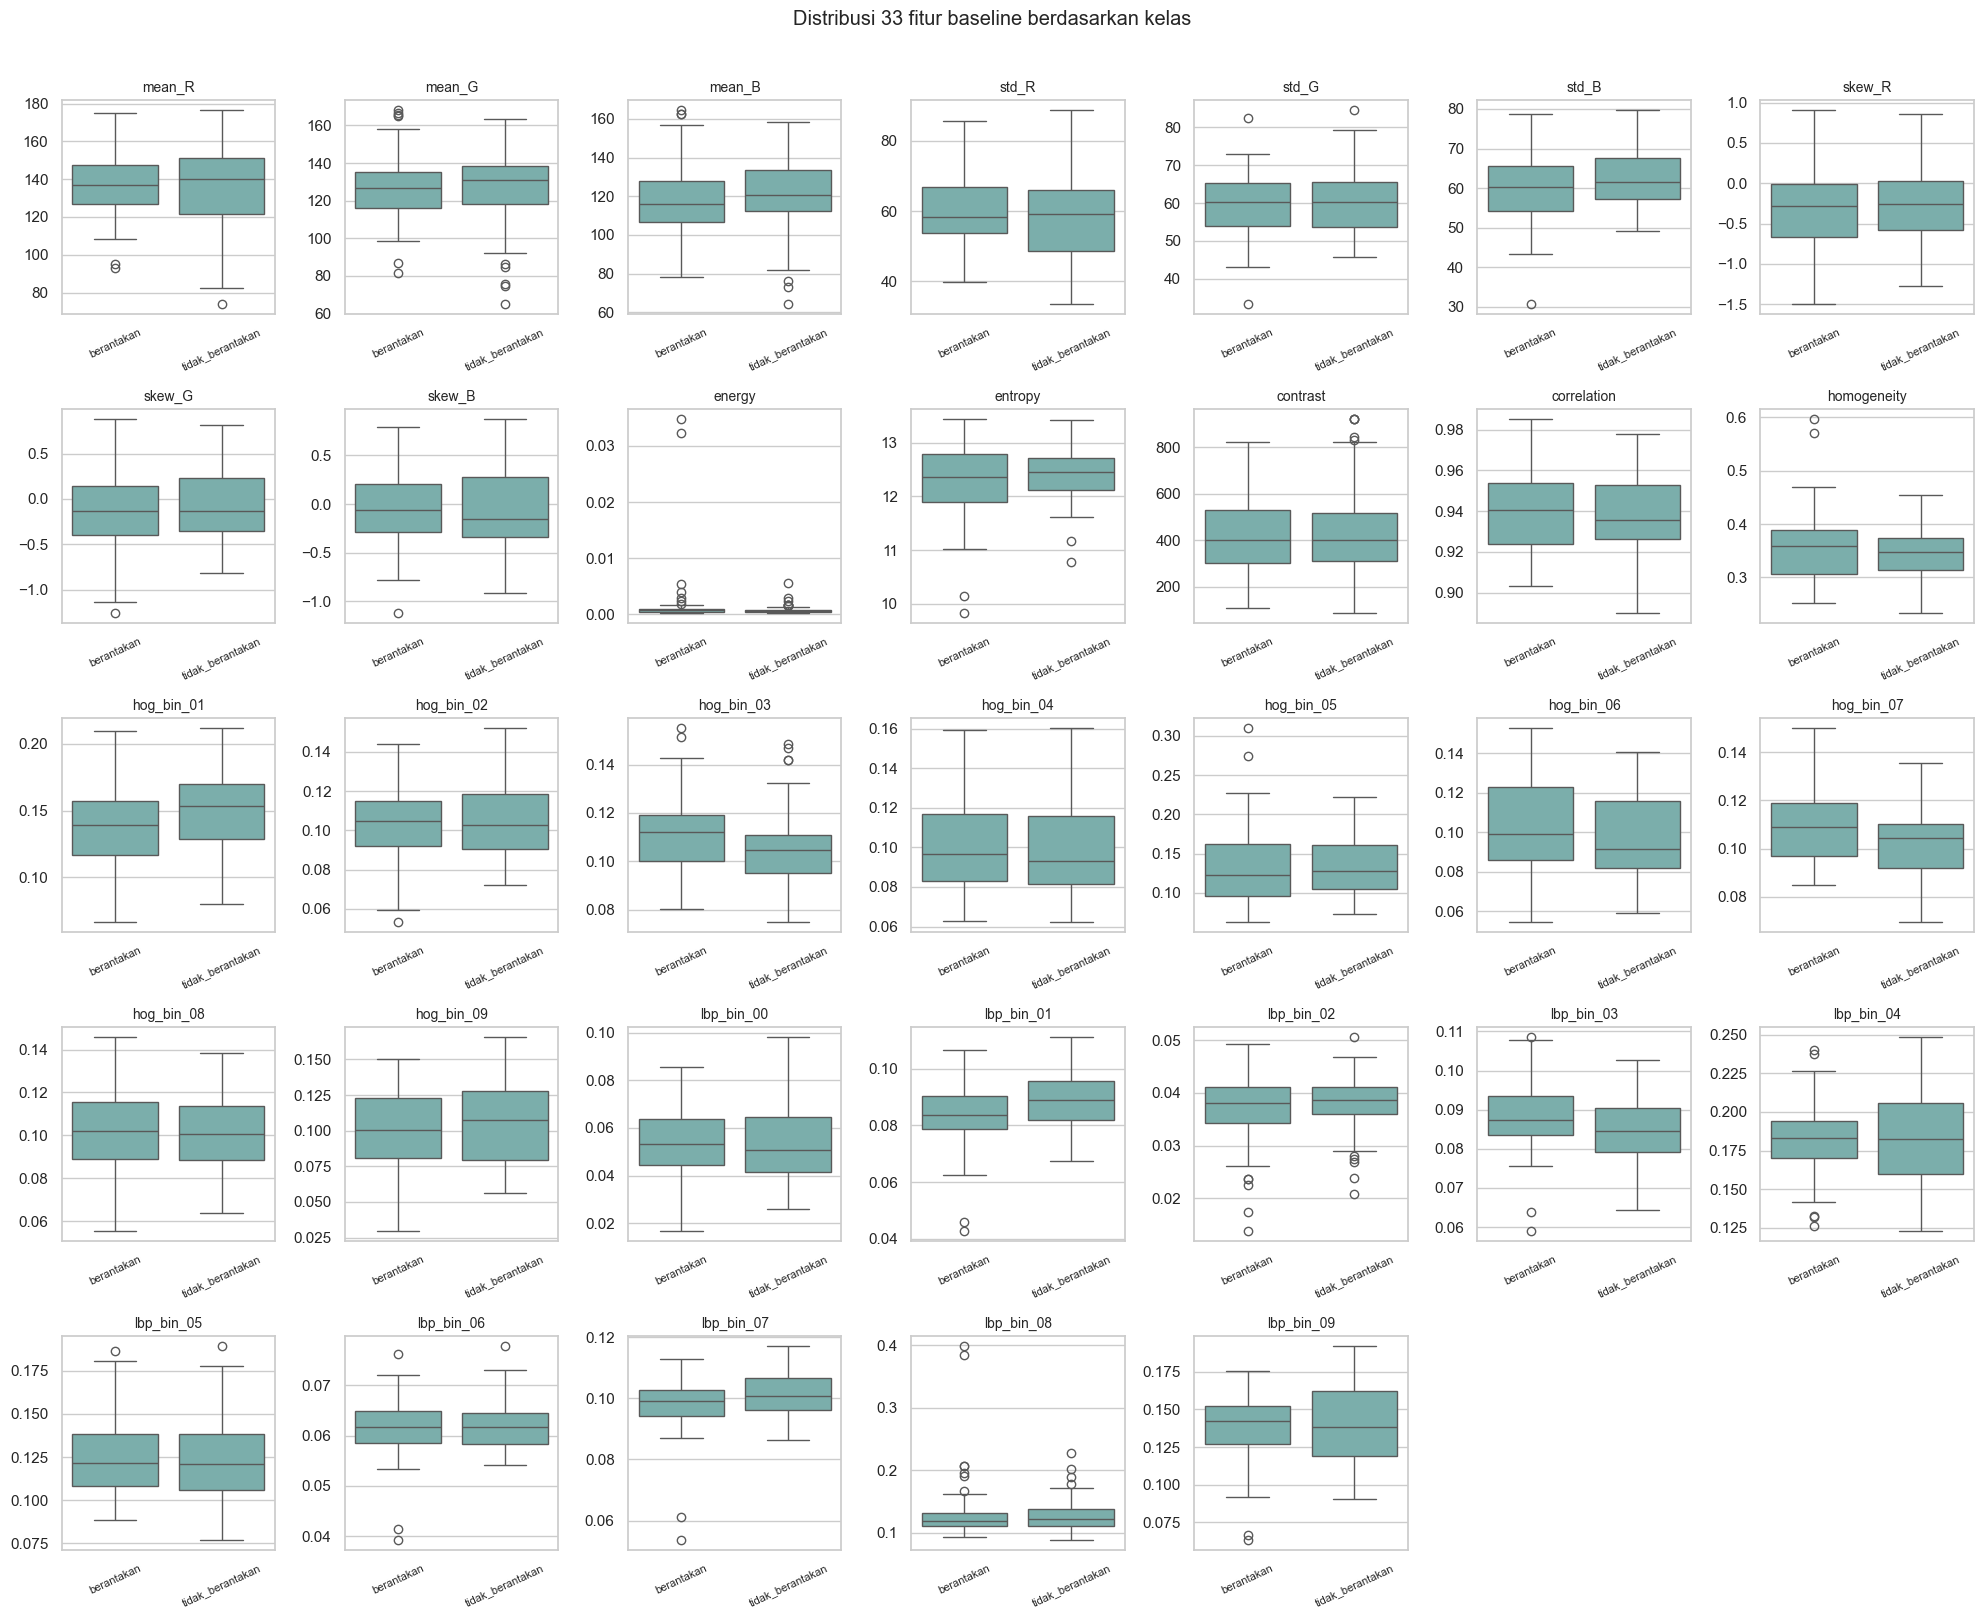

In [26]:
n_features = len(BASE_FEATURES)
n_cols = 7
n_rows = int(np.ceil(n_features / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 3.2 * n_rows))
for ax, feature in zip(axes.flat, BASE_FEATURES):
    sns.boxplot(data=df_base, x="label", y=feature, order=CLASS_LABELS, ax=ax, color="#72b7b2")
    ax.set_title(feature, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=25, labelsize=8)
for ax in axes.flat[n_features:]:
    ax.set_visible(False)
fig.suptitle("Distribusi 33 fitur baseline berdasarkan kelas", y=1.01)
plt.tight_layout()
plt.show()


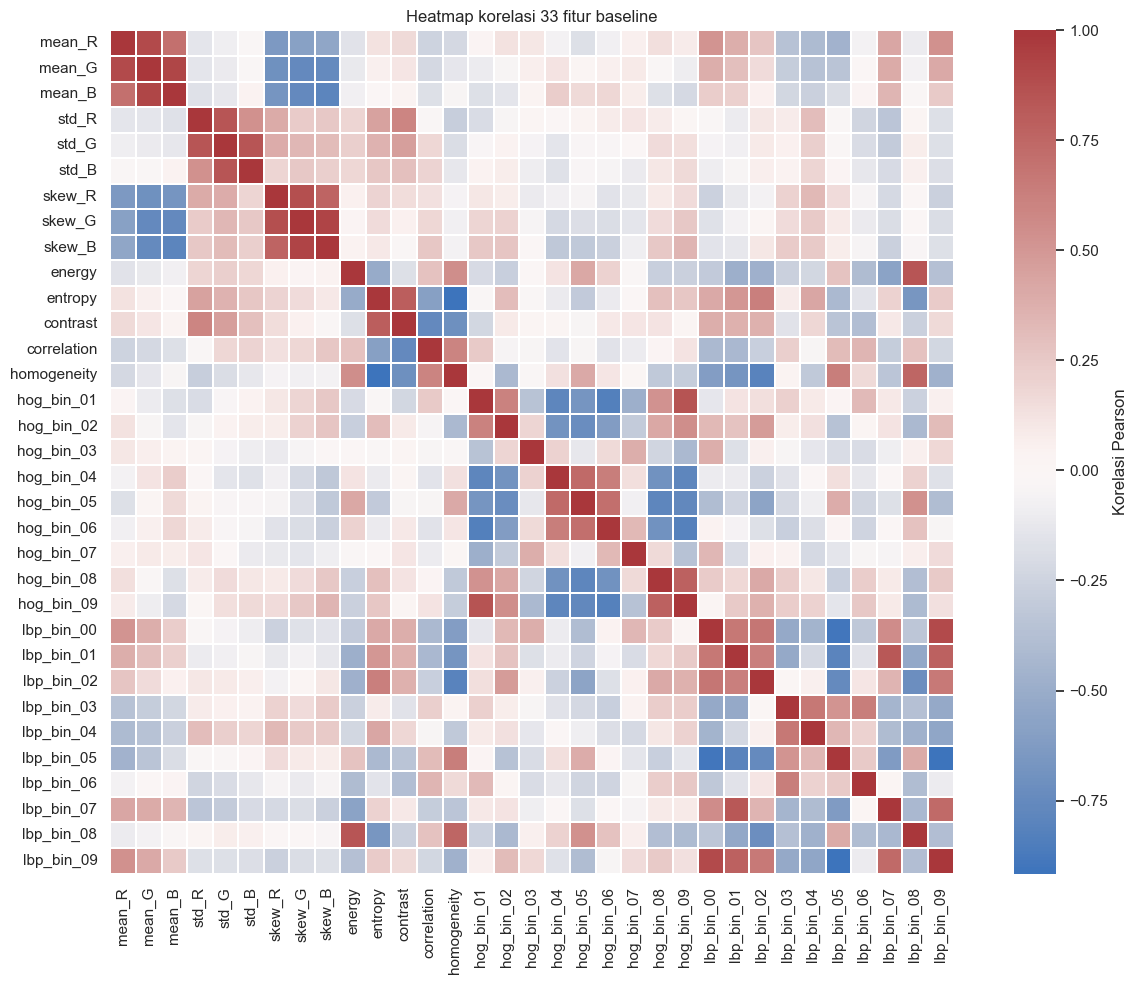

Sepuluh pasangan fitur dengan korelasi absolut tertinggi:


,fitur_1,fitur_2,korelasi
203,skew_G,skew_B,0.9258
32,mean_G,mean_B,0.9225
277,entropy,homogeneity,-0.9160
521,lbp_bin_05,lbp_bin_09,-0.9095
0,mean_R,mean_G,0.9007
487,lbp_bin_00,lbp_bin_05,-0.8969
491,lbp_bin_00,lbp_bin_09,0.8954
177,skew_R,skew_G,0.8760
364,hog_bin_01,hog_bin_09,0.8538
93,std_R,std_G,0.8498


In [27]:
correlation = df_base[BASE_FEATURES].corr()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(correlation, cmap="vlag", center=0, square=True, linewidths=0.2,
            cbar_kws={"label": "Korelasi Pearson"}, ax=ax)
ax.set_title("Heatmap korelasi 33 fitur baseline")
plt.tight_layout()
plt.show()

high_pairs = (
    correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
    .stack()
    .rename("korelasi")
    .reset_index()
    .rename(columns={"level_0": "fitur_1", "level_1": "fitur_2"})
)
high_pairs = high_pairs.reindex(high_pairs["korelasi"].abs().sort_values(ascending=False).index)
print("Sepuluh pasangan fitur dengan korelasi absolut tertinggi:")
display(high_pairs.head(10).round(4))


## 13. Train-Test Split

Pembagian dilakukan **sebelum** pemilihan model, feature selection, dan tuning:

- 80% training, 20% testing.
- Stratified terhadap label.
- `random_state=42`.
- `filename` tidak masuk ke `X`.

Seluruh eksperimen (tujuh model, feature selection, tuning, ablation) memakai indeks train/test yang sama. Opsi `SPLIT_BY_GROUP=True` memakai `GroupShuffleSplit` berdasarkan ID sepatu (`24-xxx`) agar foto dari sepatu yang sama tidak muncul di train sekaligus test.


In [28]:
df_model = df_model_data.copy()
X_all = df_model[BASE_FEATURES].to_numpy(dtype=np.float64)
label_to_index = {label: index for index, label in enumerate(CLASS_LABELS)}
y_all = df_model["label"].map(label_to_index).to_numpy(dtype=int)

if len(np.unique(y_all)) != 2:
    raise ValueError("Klasifikasi memerlukan tepat dua kelas.")

if SPLIT_BY_GROUP:
    groups = df_model["filename"].str.extract(r"(24-\d{3})")[0]
    groups = groups.fillna(pd.Series(df_model.index.astype(str), index=df_model.index))
    splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
    train_idx, test_idx = next(splitter.split(X_all, y_all, groups=groups))
    print("Split mode: GroupShuffleSplit berdasarkan ID sepatu (24-xxx).")
else:
    train_idx, test_idx = train_test_split(
        np.arange(len(df_model)),
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y_all,
    )
    print("Split mode: stratified train_test_split 80/20.")

X_train, X_test = X_all[train_idx], X_all[test_idx]
y_train, y_test = y_all[train_idx], y_all[test_idx]

print(f"Train: {len(train_idx)} | Test: {len(test_idx)}")
print("Distribusi train:", {label: int(np.sum(y_train == index)) for index, label in enumerate(CLASS_LABELS)})
print("Distribusi test :", {label: int(np.sum(y_test == index)) for index, label in enumerate(CLASS_LABELS)})

if len(np.unique(y_train)) != 2 or len(np.unique(y_test)) != 2:
    raise ValueError("Setelah split, salah satu subset tidak memuat kedua kelas.")

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
print(f"Cross-validation: StratifiedKFold(n_splits={N_SPLITS}, shuffle=True, random_state={RANDOM_STATE})")


Split mode: stratified train_test_split 80/20.
Train: 155 | Test: 39
Distribusi train: {'berantakan': 77, 'tidak_berantakan': 78}
Distribusi test : {'berantakan': 20, 'tidak_berantakan': 19}
Cross-validation: StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


## 14. Baseline Machine Learning Comparison

Tujuh algoritma dibandingkan pada **data training saja** dengan Stratified 5-Fold CV:

| No | Model | Konfigurasi baseline |
|---|---|---|
| 1 | SVM (RBF) | `StandardScaler` + `SVC(C=10, gamma=0.01, kernel="rbf")` |
| 2 | Random Forest | `RandomForestClassifier(n_estimators=500)` |
| 3 | Extra Trees | `ExtraTreesClassifier(n_estimators=500)` |
| 4 | K-NN | `StandardScaler` + `KNeighborsClassifier(5, weights="distance")` |
| 5 | Logistic Regression | `StandardScaler` + `LogisticRegression(max_iter=5000, C=0.5)` |
| 6 | Gradient Boosting | `GradientBoostingClassifier()` |
| 7 | LightGBM | `LGBMClassifier(verbosity=-1)` |

`StandardScaler` berada di dalam Pipeline sehingga hanya di-fit pada fold training. Model pohon tidak memakai scaling. LightGBM tidak diganti model lain bila tidak tersedia; notebook hanya memberi keterangan.


In [29]:
MODEL_ORDER = [
    "SVM (RBF)",
    "Random Forest",
    "Extra Trees",
    "K-NN (k=5)",
    "Logistic Regression",
    "Gradient Boosting",
    "LightGBM",
]


def build_estimator(model_name: str, selector=None) -> Pipeline:
    """Bangun Pipeline bersih untuk satu model; scaler hanya untuk model yang butuh."""
    steps = []
    if model_name == "SVM (RBF)":
        steps.append(("scaler", StandardScaler()))
        estimator = SVC(C=10, gamma=0.01, kernel="rbf", random_state=RANDOM_STATE)
    elif model_name == "Random Forest":
        estimator = RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)
    elif model_name == "Extra Trees":
        estimator = ExtraTreesClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)
    elif model_name == "K-NN (k=5)":
        steps.append(("scaler", StandardScaler()))
        estimator = KNeighborsClassifier(n_neighbors=5, weights="distance")
    elif model_name == "Logistic Regression":
        steps.append(("scaler", StandardScaler()))
        estimator = LogisticRegression(max_iter=5000, C=0.5, random_state=RANDOM_STATE)
    elif model_name == "Gradient Boosting":
        estimator = GradientBoostingClassifier(random_state=RANDOM_STATE)
    elif model_name == "LightGBM":
        estimator = LGBMClassifier(random_state=RANDOM_STATE, verbosity=-1)
    else:
        raise ValueError(f"Model tidak dikenal: {model_name}")

    if selector is not None:
        steps.append(("selector", clone(selector)))
    steps.append(("model", estimator))
    return Pipeline(steps)


def available_model_names() -> list:
    names = list(MODEL_ORDER)
    if not LIGHTGBM_AVAILABLE:
        names.remove("LightGBM")
    return names


def build_models(selector=None) -> dict:
    return {name: build_estimator(name, selector=selector) for name in available_model_names()}


def evaluate_models(models: dict, X, y, cv) -> tuple:
    """CV accuracy tiap model; mengembalikan tabel + skor per fold."""
    rows, scores_by_model = [], {}
    fold_columns = [f"fold_{index}" for index in range(1, N_SPLITS + 1)]

    for name, model in models.items():
        scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", n_jobs=1)
        scores_by_model[name] = scores
        row = {"model": name}
        row.update(dict(zip(fold_columns, scores)))
        row["mean_accuracy"] = float(scores.mean())
        row["std_accuracy"] = float(scores.std(ddof=0))
        rows.append(row)

    table = (
        pd.DataFrame(rows)
        .sort_values(["mean_accuracy", "std_accuracy"], ascending=[False, True])
        .reset_index(drop=True)
    )
    return table, scores_by_model


def select_best(table: pd.DataFrame, tolerance: float = 0.001) -> tuple:
    """Pilih mean CV tertinggi; bila selisih <= tolerance, pilih std terkecil."""
    top = table["mean_accuracy"].max()
    candidates = table[table["mean_accuracy"] >= top - tolerance]
    best = candidates.sort_values(["std_accuracy", "mean_accuracy"], ascending=[True, False]).iloc[0]
    alternatives = table[table["model"] != best["model"]].head(2)
    return best, alternatives


def print_selection(best_row, alternatives, scores_by_model):
    print(f"Model terbaik: {best_row['model']}")
    print(f"  Mean CV accuracy : {best_row['mean_accuracy']:.4f}")
    print(f"  Std CV accuracy  : {best_row['std_accuracy']:.4f}")
    print("  Accuracy per fold:", " | ".join(f"{score:.4f}" for score in scores_by_model[best_row["model"]]))
    print("Model alternatif (hampir sama):")
    for _, row in alternatives.iterrows():
        print(f"  - {row['model']}: mean={row['mean_accuracy']:.4f}, std={row['std_accuracy']:.4f}")


if not LIGHTGBM_AVAILABLE:
    print("PERINGATAN: LightGBM tidak terpasang. Model 7 tidak dijalankan dan TIDAK diganti model lain.")
    print("Aktifkan INSTALL_DEPENDENCIES=True (paket lightgbm) untuk menjalankannya.")

print("Model yang akan diuji:", ", ".join(available_model_names()))


Model yang akan diuji: SVM (RBF), Random Forest, Extra Trees, K-NN (k=5), Logistic Regression, Gradient Boosting, LightGBM


In [30]:
baseline_models = build_models()
hasil_models, cv_scores = evaluate_models(baseline_models, X_train, y_train, cv)
best_baseline, alternatives_baseline = select_best(hasil_models)

print(f"Perbandingan {len(hasil_models)} model pada data training (CV):")
display(hasil_models.round(4))
print_selection(best_baseline, alternatives_baseline, cv_scores)


  File "C:\laragon\bin\python\python-3.10\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\laragon\bin\python\python-3.10\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\laragon\bin\python\python-3.10\lib\subprocess.py", line 969, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\laragon\bin\python\python-3.10\lib\subprocess.py", line 1438, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


Perbandingan 7 model pada data training (CV):


,model,fold_1,fold_2,fold_3,fold_4,fold_5,mean_accuracy,std_accuracy
0,Extra Trees,0.9032,0.6129,0.8065,0.7419,0.7097,0.7548,0.0970
1,SVM (RBF),0.8387,0.6129,0.8387,0.8065,0.6774,0.7548,0.0926
2,Random Forest,0.8387,0.6129,0.8387,0.7742,0.6452,0.7419,0.0957
3,K-NN (k=5),0.8387,0.6452,0.6774,0.7097,0.7742,0.7290,0.0695
4,Gradient Boosting,0.8065,0.6129,0.7742,0.7742,0.6774,0.7290,0.0724
5,LightGBM,0.7742,0.5484,0.7097,0.8387,0.6774,0.7097,0.0978
6,Logistic Regression,0.6774,0.5161,0.8065,0.7419,0.6774,0.6839,0.0966


Model terbaik: SVM (RBF)
  Mean CV accuracy : 0.7548
  Std CV accuracy  : 0.0926
  Accuracy per fold: 0.8387 | 0.6129 | 0.8387 | 0.8065 | 0.6774
Model alternatif (hampir sama):
  - Extra Trees: mean=0.7548, std=0.0970
  - Random Forest: mean=0.7419, std=0.0957


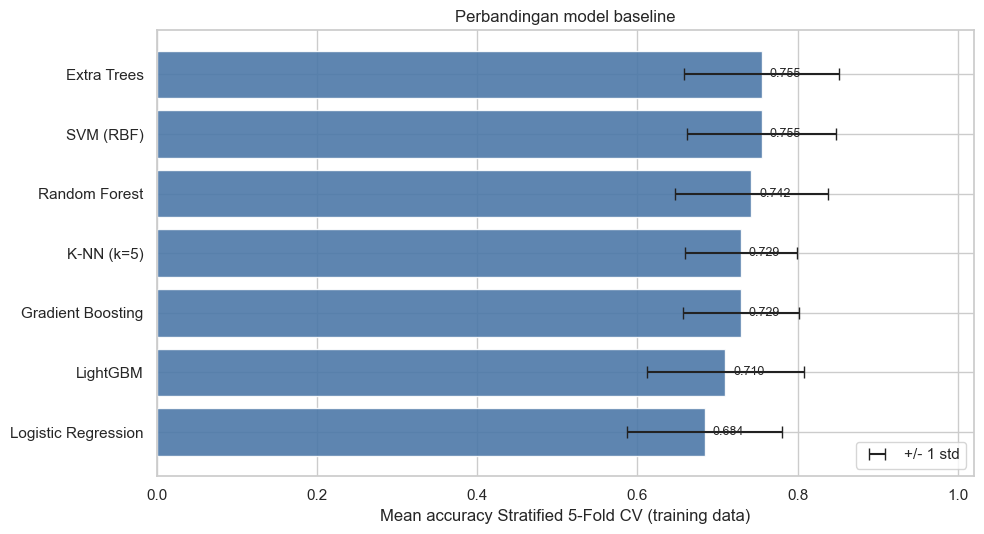

Disimpan: C:\laragon\www\messy-shoe-cv\model.yolo\outputs\evaluations\comparison_models.csv


In [31]:
plot_data = hasil_models.sort_values("mean_accuracy", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5.5))
positions = np.arange(len(plot_data))
ax.barh(positions, plot_data["mean_accuracy"], color="#4c78a8", alpha=0.9)
ax.errorbar(plot_data["mean_accuracy"], positions, xerr=plot_data["std_accuracy"],
            fmt="none", ecolor="#222222", capsize=4, label="+/- 1 std")
ax.set_yticks(positions, plot_data["model"])
ax.set_xlim(0, 1.02)
ax.set_xlabel("Mean accuracy Stratified 5-Fold CV (training data)")
ax.set_title("Perbandingan model baseline")
ax.legend(loc="lower right")
for position, value in zip(positions, plot_data["mean_accuracy"]):
    ax.text(value + 0.01, position, f"{value:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

hasil_models.to_csv(EVAL_DIR / "comparison_models.csv", index=False)
print(f"Disimpan: {EVAL_DIR / 'comparison_models.csv'}")


## 15. Feature Selection

Perbandingan strategi feature selection memakai model terbaik baseline dan **hanya data training** di dalam Pipeline CV:

- Tanpa seleksi (33 fitur).
- `SelectKBest` dengan Mutual Information, k = 8 / 12 / 16.
- `RFE` dengan Random Forest, 8 / 12 fitur.

Selector diletakkan di dalam Pipeline sehingga di-fit ulang pada setiap fold. Hasil terbaik dipakai pada tahap tuning dan ablation bila memberi perbaikan bermakna (> 0.002).


In [32]:
n_available = len(BASE_FEATURES)


def make_selector(kind: str, k: int):
    if kind == "none":
        return None
    if kind == "kbest":
        return SelectKBest(score_func=mutual_info_classif, k=min(k, n_available))
    if kind == "rfe":
        return RFE(
            estimator=RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
            n_features_to_select=min(k, n_available),
            step=2,
        )
    raise ValueError(kind)


fs_strategies = {
    "tanpa seleksi": {"kind": "none", "k": n_available},
    "SelectKBest MI k=8": {"kind": "kbest", "k": 8},
    "SelectKBest MI k=12": {"kind": "kbest", "k": 12},
    "SelectKBest MI k=16": {"kind": "kbest", "k": 16},
    "RFE RF k=8": {"kind": "rfe", "k": 8},
    "RFE RF k=12": {"kind": "rfe", "k": 12},
}

fs_rows = []
fs_selectors = {}
for label, config in fs_strategies.items():
    selector = make_selector(config["kind"], config["k"])
    model = build_estimator(best_baseline["model"], selector=selector)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=1)
    fs_selectors[label] = selector
    fs_rows.append({
        "strategi": label,
        "mean_accuracy": float(scores.mean()),
        "std_accuracy": float(scores.std(ddof=0)),
    })

hasil_fs = pd.DataFrame(fs_rows).sort_values("mean_accuracy", ascending=False).reset_index(drop=True)
display(hasil_fs.round(4))

best_fs_row = hasil_fs.iloc[0]
baseline_score = float(hasil_fs.loc[hasil_fs["strategi"] == "tanpa seleksi", "mean_accuracy"].iloc[0])
improvement = float(best_fs_row["mean_accuracy"] - baseline_score)
USE_FS = (best_fs_row["strategi"] != "tanpa seleksi") and (improvement > 0.002)
best_selector = fs_selectors[best_fs_row["strategi"]] if USE_FS else None

print(f"Strategi terbaik: {best_fs_row['strategi']} (mean={best_fs_row['mean_accuracy']:.4f})")
print(f"Perbaikan vs tanpa seleksi: {improvement:+.4f}")
print("Feature selection dipakai pada tahap berikutnya:", "YA" if USE_FS else "TIDAK")

hasil_fs.to_csv(EVAL_DIR / "comparison_feature_selection.csv", index=False)


,strategi,mean_accuracy,std_accuracy
0,tanpa seleksi,0.7548,0.0926
1,SelectKBest MI k=16,0.6710,0.1125
2,RFE RF k=12,0.6516,0.1231
3,SelectKBest MI k=8,0.6387,0.0428
4,SelectKBest MI k=12,0.6387,0.1434
5,RFE RF k=8,0.6065,0.1281


Strategi terbaik: tanpa seleksi (mean=0.7548)
Perbaikan vs tanpa seleksi: +0.0000
Feature selection dipakai pada tahap berikutnya: TIDAK


In [33]:
if USE_FS:
    probe = build_estimator(best_baseline["model"], selector=best_selector)
    probe.fit(X_train, y_train)
    selector_fitted = probe.named_steps["selector"]
    if hasattr(selector_fitted, "get_support"):
        selected_mask = selector_fitted.get_support()
        selected_names = [name for name, keep in zip(BASE_FEATURES, selected_mask) if keep]
    else:
        selected_names = BASE_FEATURES
    print(f"Fitur dipertahankan ({len(selected_names)}):")
    print(", ".join(selected_names))
else:
    print("Tidak ada seleksi fitur yang dipakai; seluruh 33 fitur baseline dipertahankan.")


Tidak ada seleksi fitur yang dipakai; seluruh 33 fitur baseline dipertahankan.


## 16. Hyperparameter Tuning

Tuning hanya memakai data training dengan `GridSearchCV` dan Stratified 5-Fold CV yang sama. Testing data tidak digunakan pada tahap ini.


In [34]:
PARAM_GRIDS = {
    "SVM (RBF)": {
        "model__C": [1, 10, 100],
        "model__gamma": [0.001, 0.01, 0.1],
    },
    "Random Forest": {
        "model__n_estimators": [300, 500],
        "model__max_depth": [None, 10],
        "model__min_samples_leaf": [1, 2],
    },
    "Extra Trees": {
        "model__n_estimators": [300, 500],
        "model__max_depth": [None, 10],
        "model__min_samples_leaf": [1, 2],
    },
    "K-NN (k=5)": {
        "model__n_neighbors": [3, 5, 7, 9],
        "model__weights": ["uniform", "distance"],
    },
    "Logistic Regression": {
        "model__C": [0.1, 0.5, 1.0, 5.0],
        "model__solver": ["lbfgs", "liblinear"],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3],
    },
    "LightGBM": {
        "model__n_estimators": [100, 300],
        "model__learning_rate": [0.05, 0.1],
        "model__num_leaves": [15, 31],
    },
}


def tune_model(model_name: str, X, y, selector, verbose: bool = True):
    """GridSearchCV pada data training; mengembalikan objek GridSearchCV terbaik."""
    pipeline = build_estimator(model_name, selector=selector)
    grid = GridSearchCV(
        pipeline,
        param_grid=PARAM_GRIDS[model_name],
        cv=cv,
        scoring="accuracy",
        n_jobs=1,
        refit=True,
    )
    grid.fit(X, y)
    if verbose:
        print(f"Tuning {model_name}: best CV accuracy = {grid.best_score_:.4f}")
        print("Parameter terbaik:", grid.best_params_)
    return grid


In [35]:
tuning_start = pd.Timestamp.now()
grid_baseline = tune_model(best_baseline["model"], X_train, y_train, best_selector)
print(f"Durasi tuning: {(pd.Timestamp.now() - tuning_start).total_seconds():.1f} detik")

before_after = pd.DataFrame({
    "tahap": ["sebelum tuning", "sesudah tuning"],
    "mean_cv_accuracy": [float(best_baseline["mean_accuracy"]), float(grid_baseline.best_score_)],
    "std_cv_accuracy": [
        float(best_baseline["std_accuracy"]),
        float(grid_baseline.cv_results_["std_test_score"][grid_baseline.best_index_]),
    ],
})
display(before_after.round(4))


Tuning SVM (RBF): best CV accuracy = 0.8194
Parameter terbaik: {'model__C': 100, 'model__gamma': 0.01}
Durasi tuning: 0.2 detik


,tahap,mean_cv_accuracy,std_cv_accuracy
0,sebelum tuning,0.7548,0.0926
1,sesudah tuning,0.8194,0.1052


## 17. Feature Ablation Experiments

Enam kombinasi fitur diuji dengan split train/test dan fold CV yang sama:

| Eksperimen | Fitur |
|---|---|
| E1 | RGB + GLCM |
| E2 | RGB + GLCM + HOG |
| E3 | RGB + GLCM + LBP |
| E4 | YOLO Geometric + Spatial |
| E5 | RGB + GLCM + HOG + LBP |
| E6 | RGB + GLCM + HOG + LBP + YOLO |

Setiap eksperimen memilih model terbaiknya sendiri berdasarkan CV, lalu di-tuning pada training data dan dievaluasi satu kali pada testing data. Kombinasi fitur terbaik pada Section 18 ditentukan dari **tuned CV** tertinggi, karena semua eksperimen sudah di-tuning dengan fold yang sama. E4/E6 otomatis ditandai *skipped* bila fitur YOLO tidak tersedia. Klaim kontribusi YOLO hanya boleh dibuat jika E6 benar-benar menghasilkan angka.


In [36]:
EXPERIMENTS = {
    "E1": {"nama": "RGB + GLCM", "fitur": RGB_FEATURES + GLCM_FEATURES},
    "E2": {"nama": "RGB + GLCM + HOG", "fitur": RGB_FEATURES + GLCM_FEATURES + HOG_FEATURES},
    "E3": {"nama": "RGB + GLCM + LBP", "fitur": RGB_FEATURES + GLCM_FEATURES + LBP_FEATURES},
    "E4": {"nama": "YOLO Geometric + Spatial", "fitur": YOLO_FEATURES},
    "E5": {"nama": "RGB + GLCM + HOG + LBP", "fitur": BASE_FEATURES},
    "E6": {"nama": "RGB + GLCM + HOG + LBP + YOLO", "fitur": HYBRID_FEATURES},
}

available_columns = set(df_model.columns)

for experiment in EXPERIMENTS.values():
    experiment["tersedia"] = set(experiment["fitur"]).issubset(available_columns)

display(pd.DataFrame([
    {"eksperimen": key, "kombinasi": value["nama"], "jumlah_fitur": len(value["fitur"]),
     "tersedia": value["tersedia"]}
    for key, value in EXPERIMENTS.items()
]))


,eksperimen,kombinasi,jumlah_fitur,tersedia
0,E1,RGB + GLCM,14,True
1,E2,RGB + GLCM + HOG,23,True
2,E3,RGB + GLCM + LBP,24,True
3,E4,YOLO Geometric + Spatial,16,False
4,E5,RGB + GLCM + HOG + LBP,33,True
5,E6,RGB + GLCM + HOG + LBP + YOLO,49,False


In [37]:
ablation_rows = []
ablation_models = {}
ablation_tuned = {}
ablation_features = {}

for key, experiment in EXPERIMENTS.items():
    features = experiment["fitur"]
    if not experiment["tersedia"]:
        ablation_rows.append({
            "eksperimen": key, "kombinasi": experiment["nama"], "jumlah_fitur": len(features),
            "best_model": "-", "cv_mean": np.nan, "cv_std": np.nan,
            "test_accuracy": np.nan, "status": "skipped (fitur YOLO tidak tersedia)",
        })
        print(f"{key}: dilewati, fitur YOLO tidak tersedia.")
        continue

    X_exp = df_model[features].to_numpy(dtype=np.float64)
    X_train_exp, X_test_exp = X_exp[train_idx], X_exp[test_idx]

    models_exp = build_models(selector=best_selector)
    table_exp, scores_exp = evaluate_models(models_exp, X_train_exp, y_train, cv)
    best_exp, _ = select_best(table_exp)
    grid_exp = tune_model(best_exp["model"], X_train_exp, y_train, best_selector, verbose=False)
    test_accuracy = float(accuracy_score(y_test, grid_exp.predict(X_test_exp)))

    ablation_models[key] = models_exp
    ablation_tuned[key] = grid_exp
    ablation_features[key] = features
    ablation_rows.append({
        "eksperimen": key,
        "kombinasi": experiment["nama"],
        "jumlah_fitur": len(features),
        "best_model": best_exp["model"],
        "cv_mean": float(best_exp["mean_accuracy"]),
        "cv_std": float(best_exp["std_accuracy"]),
        "tuned_cv_mean": float(grid_exp.best_score_),
        "tuned_cv_std": float(grid_exp.cv_results_["std_test_score"][grid_exp.best_index_]),
        "test_accuracy": test_accuracy,
        "status": "ok",
    })
    print(f"{key}: {best_exp['model']} | CV={best_exp['mean_accuracy']:.4f} "
          f"+/- {best_exp['std_accuracy']:.4f} | tuned CV={grid_exp.best_score_:.4f} | test={test_accuracy:.4f}")

hasil_ablation = pd.DataFrame(ablation_rows)
display(hasil_ablation.round(4))
hasil_ablation.to_csv(EVAL_DIR / "comparison_features.csv", index=False)
print(f"Disimpan: {EVAL_DIR / 'comparison_features.csv'}")


E1: Extra Trees | CV=0.7548 +/- 0.0880 | tuned CV=0.7806 | test=0.6667


E2: Extra Trees | CV=0.7419 +/- 0.0866 | tuned CV=0.7613 | test=0.6667


E3: Extra Trees | CV=0.7935 +/- 0.0831 | tuned CV=0.7935 | test=0.7179
E4: dilewati, fitur YOLO tidak tersedia.


E5: SVM (RBF) | CV=0.7548 +/- 0.0926 | tuned CV=0.8194 | test=0.7179
E6: dilewati, fitur YOLO tidak tersedia.


,eksperimen,kombinasi,jumlah_fitur,best_model,cv_mean,cv_std,tuned_cv_mean,tuned_cv_std,test_accuracy,status
0,E1,RGB + GLCM,14,Extra Trees,0.7548,0.0880,0.7806,0.0875,0.6667,ok
1,E2,RGB + GLCM + HOG,23,Extra Trees,0.7419,0.0866,0.7613,0.0880,0.6667,ok
2,E3,RGB + GLCM + LBP,24,Extra Trees,0.7935,0.0831,0.7935,0.0831,0.7179,ok
3,E4,YOLO Geometric + Spatial,16,-,NaN,NaN,NaN,NaN,NaN,skipped (fitur YOLO tidak tersedia)
4,E5,RGB + GLCM + HOG + LBP,33,SVM (RBF),0.7548,0.0926,0.8194,0.1052,0.7179,ok
5,E6,RGB + GLCM + HOG + LBP + YOLO,49,-,NaN,NaN,NaN,NaN,NaN,skipped (fitur YOLO tidak tersedia)


Disimpan: C:\laragon\www\messy-shoe-cv\model.yolo\outputs\evaluations\comparison_features.csv


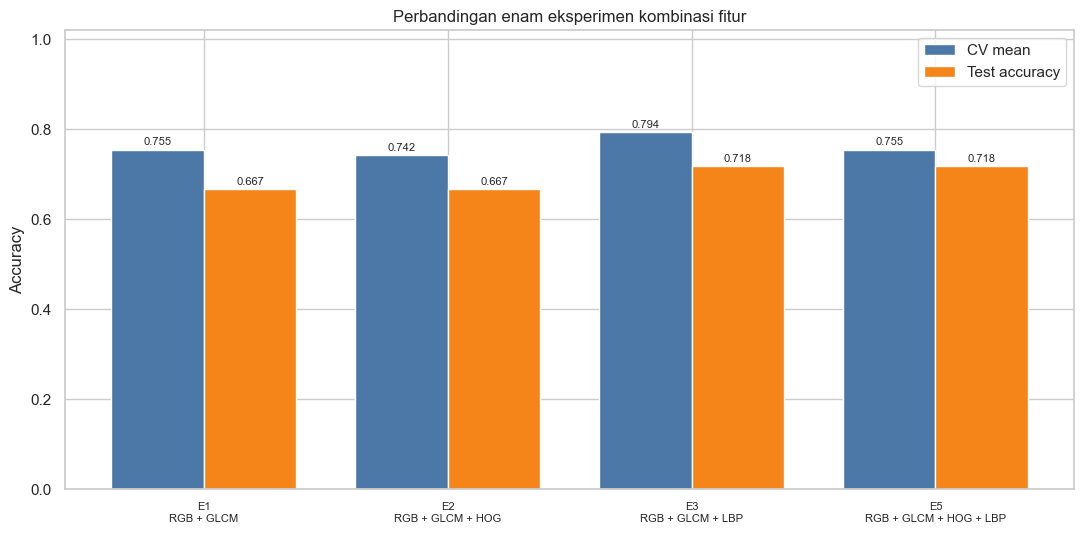

In [38]:
plot_frame = hasil_ablation.dropna(subset=["cv_mean"]).copy()
if plot_frame.empty:
    print("Tidak ada eksperimen yang dapat divisualisasikan.")
else:
    positions = np.arange(len(plot_frame))
    width = 0.38
    fig, ax = plt.subplots(figsize=(11, 5.5))
    ax.bar(positions - width / 2, plot_frame["cv_mean"], width, label="CV mean", color="#4c78a8")
    ax.bar(positions + width / 2, plot_frame["test_accuracy"], width, label="Test accuracy", color="#f58518")
    ax.set_xticks(positions, [f"{row.eksperimen}\n{row.kombinasi}" for row in plot_frame.itertuples()],
                  fontsize=8)
    ax.set_ylim(0, 1.02)
    ax.set_ylabel("Accuracy")
    ax.set_title("Perbandingan enam eksperimen kombinasi fitur")
    ax.legend()
    for position, value in zip(positions, plot_frame["cv_mean"]):
        ax.text(position - width / 2, value + 0.01, f"{value:.3f}", ha="center", fontsize=8)
    for position, value in zip(positions, plot_frame["test_accuracy"]):
        ax.text(position + width / 2, value + 0.01, f"{value:.3f}", ha="center", fontsize=8)
    plt.tight_layout()
    plt.show()


## 18. Final Model Evaluation

Model final ditentukan dari eksperimen dengan **mean CV accuracy tertinggi setelah tuning** (bukan dari test accuracy). Setiap eksperimen sudah di-tuning pada data training dengan fold yang sama, sehingga perbandingan dilakukan pada kondisi terbaik masing-masing. Model kemudian dilatih ulang memakai seluruh data training dan dievaluasi **satu kali** pada data testing.

Artefak yang disimpan:

- `outputs/evaluations/comparison_models.csv`
- `outputs/evaluations/comparison_features.csv`
- `outputs/evaluations/classification_report.txt`
- `outputs/evaluations/confusion_matrix.png`
- `outputs/evaluations/feature_importance.png` (bila model mendukung)
- `outputs/models/best_classifier.pkl`


In [39]:
valid_experiments = hasil_ablation.dropna(subset=["cv_mean"]).copy()
best_experiment_row = valid_experiments.sort_values(
    ["tuned_cv_mean", "tuned_cv_std"], ascending=[False, True]
).iloc[0]
best_experiment_key = best_experiment_row["eksperimen"]

final_model = clone(ablation_tuned[best_experiment_key].best_estimator_)
final_features = ablation_features[best_experiment_key]
X_final_train = df_model[final_features].to_numpy(dtype=np.float64)[train_idx]
X_final_test = df_model[final_features].to_numpy(dtype=np.float64)[test_idx]

final_model.fit(X_final_train, y_train)
y_pred = final_model.predict(X_final_test)
final_test_accuracy = float(accuracy_score(y_test, y_pred))
final_cv_accuracy = float(best_experiment_row["tuned_cv_mean"])
final_cv_std = float(best_experiment_row["tuned_cv_std"])

print(f"Eksperimen terbaik : {best_experiment_key} ({best_experiment_row['kombinasi']})")
print(f"Model terbaik      : {best_experiment_row['best_model']}")
print(f"CV mean accuracy   : {final_cv_accuracy:.4f} +/- {final_cv_std:.4f} (setelah tuning)")
print(f"Test accuracy      : {final_test_accuracy:.4f} ({final_test_accuracy * 100:.2f}%)")
print("Parameter terbaik  :", ablation_tuned[best_experiment_key].best_params_)


Eksperimen terbaik : E5 (RGB + GLCM + HOG + LBP)
Model terbaik      : SVM (RBF)
CV mean accuracy   : 0.8194 +/- 0.1052 (setelah tuning)
Test accuracy      : 0.7179 (71.79%)
Parameter terbaik  : {'model__C': 100, 'model__gamma': 0.01}


Classification report pada testing data:
                  precision    recall  f1-score   support

      berantakan     0.6957    0.8000    0.7442        20
tidak_berantakan     0.7500    0.6316    0.6857        19

        accuracy                         0.7179        39
       macro avg     0.7228    0.7158    0.7150        39
    weighted avg     0.7221    0.7179    0.7157        39



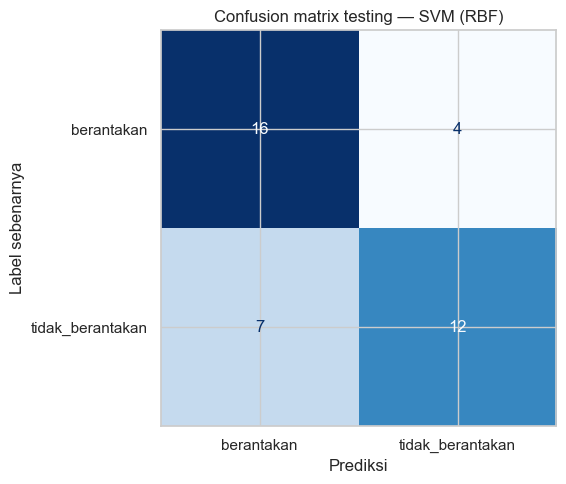

Disimpan: C:\laragon\www\messy-shoe-cv\model.yolo\outputs\evaluations\classification_report.txt
Disimpan: C:\laragon\www\messy-shoe-cv\model.yolo\outputs\evaluations\confusion_matrix.png


In [40]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(CLASS_LABELS)))
report_text = classification_report(
    y_test, y_pred, labels=np.arange(len(CLASS_LABELS)),
    target_names=CLASS_LABELS, digits=4, zero_division=0,
)

print("Classification report pada testing data:")
print(report_text)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_LABELS).plot(
    cmap="Blues", values_format="d", colorbar=False, ax=ax
)
ax.set_title(f"Confusion matrix testing — {best_experiment_row['best_model']}")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Label sebenarnya")
plt.tight_layout()
plt.savefig(EVAL_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

with open(EVAL_DIR / "classification_report.txt", "w", encoding="utf-8") as handle:
    handle.write("KLASIFIKASI KONDISI SUSUNAN SEPATU — EVALUASI FINAL\n")
    handle.write("=" * 60 + "\n")
    handle.write(f"Eksperimen        : {best_experiment_key} ({best_experiment_row['kombinasi']})\n")
    handle.write(f"Model             : {best_experiment_row['best_model']}\n")
    handle.write(f"Fitur             : {len(final_features)}\n")
    handle.write(f"CV mean accuracy  : {final_cv_accuracy:.4f} +/- {final_cv_std:.4f}\n")
    handle.write(f"Test accuracy     : {final_test_accuracy:.4f}\n")
    handle.write(f"Best params       : {ablation_tuned[best_experiment_key].best_params_}\n\n")
    handle.write("Confusion matrix (baris=aktual, kolom=prediksi):\n")
    handle.write(str(cm) + "\n\n")
    handle.write(report_text)

print(f"Disimpan: {EVAL_DIR / 'classification_report.txt'}")
print(f"Disimpan: {EVAL_DIR / 'confusion_matrix.png'}")


In [41]:
final_pipeline = final_model
estimator = final_pipeline.named_steps["model"]
feature_names = np.array(final_features)

if "selector" in final_pipeline.named_steps:
    support = final_pipeline.named_steps["selector"].get_support()
    feature_names = feature_names[support]

if hasattr(estimator, "feature_importances_"):
    importances = np.asarray(estimator.feature_importances_, dtype=np.float64)
elif hasattr(estimator, "coef_"):
    importances = np.abs(np.asarray(estimator.coef_, dtype=np.float64)).ravel()
else:
    importances = None

if importances is not None and len(importances) == len(feature_names):
    order = np.argsort(importances)[::-1][:20]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(np.arange(len(order))[::-1], importances[order], color="#54a24b")
    ax.set_yticks(np.arange(len(order))[::-1], np.array(feature_names)[order])
    ax.set_xlabel("Importance")
    ax.set_title(f"Feature importance — {best_experiment_row['best_model']}")
    plt.tight_layout()
    plt.savefig(EVAL_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Disimpan: {EVAL_DIR / 'feature_importance.png'}")
else:
    stale_plot = EVAL_DIR / "feature_importance.png"
    if stale_plot.exists():
        stale_plot.unlink()
    print(f"{best_experiment_row['best_model']} tidak menyediakan feature importance; "
          "grafik feature_importance.png tidak dibuat.")

joblib.dump(final_pipeline, MODEL_DIR / "best_classifier.pkl")
print(f"Model disimpan: {MODEL_DIR / 'best_classifier.pkl'}")


SVM (RBF) tidak menyediakan feature importance; grafik feature_importance.png tidak dibuat.
Model disimpan: C:\laragon\www\messy-shoe-cv\model.yolo\outputs\models\best_classifier.pkl


## 19. Conclusion

Bagian ini diisi otomatis dari hasil eksekusi nyata: model terbaik, kombinasi fitur terbaik, pengaruh feature selection, tuning, dan kontribusi YOLO (bila tersedia). Tidak ada angka yang ditulis manual.


In [42]:
print("RINGKASAN HASIL EKSPERIMEN")
print("=" * 70)
print(f"Jumlah citra valid      : {len(df_images)}")
print(f"Distribusi kelas        : {dict((label, int(count)) for label, count in df_base['label'].value_counts().items())}")
print(f"Fitur baseline          : {len(BASE_FEATURES)}")
print(f"Fitur YOLO tersedia     : {'ya (' + str(len(YOLO_FEATURES)) + ' fitur)' if YOLO_READY else 'tidak (Mode 1)'}")
print(f"Feature selection dipakai: {'ya' if USE_FS else 'tidak'}")
print()
print("Peringkat model baseline:")
display(hasil_models[["model", "mean_accuracy", "std_accuracy"]].round(4))
print("Peringkat eksperimen fitur:")
display(hasil_ablation[["eksperimen", "kombinasi", "best_model", "cv_mean", "cv_std",
                        "tuned_cv_mean", "tuned_cv_std", "test_accuracy", "status"]].round(4))


RINGKASAN HASIL EKSPERIMEN
Jumlah citra valid      : 194
Distribusi kelas        : {'berantakan': 97, 'tidak_berantakan': 97}
Fitur baseline          : 33
Fitur YOLO tersedia     : tidak (Mode 1)
Feature selection dipakai: tidak

Peringkat model baseline:


,model,mean_accuracy,std_accuracy
0,Extra Trees,0.7548,0.0970
1,SVM (RBF),0.7548,0.0926
2,Random Forest,0.7419,0.0957
3,K-NN (k=5),0.7290,0.0695
4,Gradient Boosting,0.7290,0.0724
5,LightGBM,0.7097,0.0978
6,Logistic Regression,0.6839,0.0966


Peringkat eksperimen fitur:


,eksperimen,kombinasi,best_model,cv_mean,cv_std,tuned_cv_mean,tuned_cv_std,test_accuracy,status
0,E1,RGB + GLCM,Extra Trees,0.7548,0.0880,0.7806,0.0875,0.6667,ok
1,E2,RGB + GLCM + HOG,Extra Trees,0.7419,0.0866,0.7613,0.0880,0.6667,ok
2,E3,RGB + GLCM + LBP,Extra Trees,0.7935,0.0831,0.7935,0.0831,0.7179,ok
3,E4,YOLO Geometric + Spatial,-,NaN,NaN,NaN,NaN,NaN,skipped (fitur YOLO tidak tersedia)
4,E5,RGB + GLCM + HOG + LBP,SVM (RBF),0.7548,0.0926,0.8194,0.1052,0.7179,ok
5,E6,RGB + GLCM + HOG + LBP + YOLO,-,NaN,NaN,NaN,NaN,NaN,skipped (fitur YOLO tidak tersedia)


In [43]:
lines = []
lines.append("# Klasifikasi Kondisi Susunan Sepatu — Hybrid Feature Extraction\n")
lines.append("Notebook: `citra-sepatu.ipynb`\n")
lines.append(f"- Jumlah citra valid: {len(df_images)}")
lines.append(f"- Kelas: {', '.join(CLASS_LABELS)}")
lines.append(f"- Fitur baseline: {len(BASE_FEATURES)} (RGB 9, GLCM 5, HOG 9, LBP 10)")
lines.append(f"- Fitur YOLO: {'tersedia (' + str(len(YOLO_FEATURES)) + ' fitur)' if YOLO_READY else 'tidak tersedia (Mode 2 tidak aktif)'}")
lines.append(f"- Model yang dibandingkan: {', '.join(available_model_names())}")
lines.append(f"- Model terbaik: {best_experiment_row['best_model']}")
lines.append(f"- Eksperimen fitur terbaik: {best_experiment_key} ({best_experiment_row['kombinasi']})")
lines.append(f"- CV mean accuracy: {final_cv_accuracy:.4f} +/- {final_cv_std:.4f}")
lines.append(f"- Test accuracy: {final_test_accuracy:.4f}")
lines.append(f"- Feature selection: {'ya' if USE_FS else 'tidak'}")
lines.append(f"- Parameter terbaik: {ablation_tuned[best_experiment_key].best_params_}")
lines.append("")
lines.append("## Struktur output")
lines.append("```text")
lines.append("outputs/")
lines.append("├── features/     # CSV per kelompok fitur, fitur_lengkap, fitur_hybrid, Excel")
lines.append("├── evaluations/  # comparison_models, comparison_features, report, confusion matrix")
lines.append("└── models/       # best_classifier.pkl")
lines.append("```")
lines.append("")
lines.append("## Keterbatasan")
lines.append("- Dataset kecil dan label tingkat gambar bersifat subjektif.")
lines.append("- Duplikat file dilaporkan, tidak dihapus otomatis.")
lines.append("- Fitur YOLO hanya tersedia bila model berkelas `shoe` tersedia; COCO tidak memilikinya.")
lines.append("- Split acak dapat mencampur foto dari sepatu yang sama; `SPLIT_BY_GROUP=True` tersedia sebagai opsi.")

readme_path = NOTEBOOK_DIR / "README.md"
readme_path.write_text("\n".join(lines) + "\n", encoding="utf-8")
print(f"README disimpan: {readme_path}")
print("\n".join(lines))


README disimpan: C:\laragon\www\messy-shoe-cv\model.yolo\README.md
# Klasifikasi Kondisi Susunan Sepatu — Hybrid Feature Extraction

Notebook: `citra-sepatu.ipynb`

- Jumlah citra valid: 194
- Kelas: berantakan, tidak_berantakan
- Fitur baseline: 33 (RGB 9, GLCM 5, HOG 9, LBP 10)
- Fitur YOLO: tidak tersedia (Mode 2 tidak aktif)
- Model yang dibandingkan: SVM (RBF), Random Forest, Extra Trees, K-NN (k=5), Logistic Regression, Gradient Boosting, LightGBM
- Model terbaik: SVM (RBF)
- Eksperimen fitur terbaik: E5 (RGB + GLCM + HOG + LBP)
- CV mean accuracy: 0.8194 +/- 0.1052
- Test accuracy: 0.7179
- Feature selection: tidak
- Parameter terbaik: {'model__C': 100, 'model__gamma': 0.01}

## Struktur output
```text
outputs/
├── features/     # CSV per kelompok fitur, fitur_lengkap, fitur_hybrid, Excel
├── evaluations/  # comparison_models, comparison_features, report, confusion matrix
└── models/       # best_classifier.pkl
```

## Keterbatasan
- Dataset kecil dan label tingkat gambar bersif